# Dynamic and Hybrid Conditioning for Compositional Image Retrieval

**Bariletti Fabio, Francavilla Sara — Deep Learning 2026, University of Trento**

---

## 1. Introduction

### 1.1 Task Definition

**Compositional Image Retrieval (CIR)** is the problem of finding images in a database that are simultaneously *visually similar* to a reference image and *semantically consistent* with a textual condition. Unlike standard text-to-image retrieval, the query here is *compositional*: it combines a visual anchor (the reference) with attribute modifiers expressed as natural language.

In this project, each query takes the form:

```
+ attribute_1 & - attribute_2 & ...
```

where `+` denotes a desired attribute and `-` denotes an attribute to be absent in the retrieved result. For example, given a reference portrait of a person, the query `+ Smiling & - Eyeglasses` asks for images of people who *look like the reference subject*, are *smiling*, and are *not wearing glasses*.

**Formal definition.** Given:
- a reference image $I_r$,
- a query string $q$ specifying positive conditions $\mathcal{P}$ and negative conditions $\mathcal{N}$,
- a database $\mathcal{D}$ of images,

retrieve a ranked list of images $I^* \in \mathcal{D}$ such that $I^*$ agrees with $I_r$ on all non-queried attributes (relaxed Hamming distance $\leq 2$), satisfies all attributes in $\mathcal{P}$, and does not satisfy any attribute in $\mathcal{N}$.

```
┌─────────────────────────────────────────────────────────────────┐
│                        CIR Task                                 │
│                                                                 │
│   Reference Image          Text Query                           │
│   ┌──────────┐         "+ Smiling & - Eyeglasses"               │
│   │  👤  I_r │                  │                                │
│   └──────────┘                  │                               │
│         │                       │                               │
│         └──────────┬────────────┘                               │
│                    ▼                                            │
│            ┌──────────────┐                                     │
│            │ Query Encoder │                                    │
│            └──────┬───────┘                                     │
│                   │                                             │
│                   ▼                                             │
│      ┌────────────────────────┐                                 │
│      │   Similarity Search    │ ◄─── Database D (19,962 imgs)   │
│      └────────────┬───────────┘                                 │
│                   │                                             │
│                   ▼                                             │
│         Top-K Retrieved Images                                  │
│         ┌────┐ ┌────┐ ┌────┐                                    │
│         │ 👤 │ │ 👤 │ │ 👤 │   ← same person, smiling,           │
│         └────┘ └────┘ └────┘     no glasses                     │
└─────────────────────────────────────────────────────────────────┘
```

---

### 1.2 Dataset and Backbone

**Dataset — CelebA.** We evaluate on the CelebA test split, comprising **19,962 face images** annotated with **40 binary attributes** (e.g., *Smiling*, *Eyeglasses*, *Male*, *Young*, *Bald*, ...). Each evaluation query is paired with a set of reference images and their associated ground-truth retrievals, defined using the relaxed Hamming criterion above.

**Backbone — CLIP ViT-B/32.** All image and text embeddings are extracted using the `openai/clip-vit-base-patch32` model from HuggingFace, producing **512-dimensional unit-norm vectors** on the unit hypersphere $\mathcal{S}^{511}$. The model is used frozen throughout — no fine-tuning is performed on CLIP weights.

**Evaluation metrics.** We report **Recall@K** and **Precision@K** at $K \in \{1, 5, 10\}$, computed per reference image and averaged across all queries.

---

### 1.3 Approach Overview

The project follows an incremental development strategy, building from a zero-shot baseline to a learned hybrid model. Each stage is motivated by the limitations of the previous one.


```
┌─────────────────────────────────────────────────────────────────────┐
│                    Development Pipeline                             │
│                                                                     │
│  ┌──────────────────────────────────────────────────────────────┐   │
│  │  STAGE 1 — Zero-Shot Baseline  [§3]                          │   │
│  │                                                              │   │
│  │  pointer = ref_emb + t_pos - t_neg                           │   │
│  │                                                              │   │
│  │  Single CLIP text embedding per attribute. No training.      │   │
│  │  All weights equal. Serves as performance floor.             │   │
│  └──────────────────────┬───────────────────────────────────────┘   │
│                         │                                           │
│          Limitation: coarse signal, no weight differentiation       │
│                         │                                           │
│                         ▼                                           │
│  ┌──────────────────────────────────────────────────────────────┐   │
│  │  STAGE 2 — Synonym & Contrary Expansion  [§4]                │   │
│  │                                                              │   │
│  │  • Per-attribute synonym/contrary pool from lexical resource │   │
│  │  • CLIP score filtering → discriminative prompts only        │   │
│  │  • Manifold-aware mean: µ_pos, µ_neg_add, µ_neg_sub          │   │
│  │                                                              │   │
│  │  Data enrichment step — shared by all later stages.          │   │
│  └──────────────────────┬───────────────────────────────────────┘   │
│                         │                                           │
│                         ▼                                           │
│  ┌──────────────────────────────────────────────────────────────┐   │
│  │  STAGE 3 — Single-Query Proof of Concept  [§5]               │   │
│  │                                                              │   │
│  │  pointer = ref + a·µ_pos - b·µ_neg_sub + c·µ_neg_add         │   │
│  │                                                              │   │
│  │  • Optimize (a, b, c) on one query: "+Chubby, -Young"        │   │
│  │  • Softplus/sigmoid reparametrization (positivity, c < a)    │   │
│  │  • Margin ranking loss on ground-truth pairs                 │   │
│  └──────────────────────┬───────────────────────────────────────┘   │
│                         │                                           │
│          Limitation: single query — weights may not generalize      │
│                         │                                           │
│                         ▼                                           │
│  ┌──────────────────────────────────────────────────────────────┐   │
│  │  STAGE 4 — Global Optimizer on All Queries  [§6]             │   │
│  │                                                              │   │
│  │  pointer = α·ref + (1-α)·(a·µ_pos - b·µ_neg_sub              │   │
│  │                           + c·µ_neg_add)  α=0.5 fixed        │   │
│  │                                                              │   │
│  │  • Same (a, b, c) shared across all 14 queries               │   │
│  │  • Trained on attribute-based pairs (Hamming ≤ 2 GT)         │   │
│  │  • Adam, margin loss.                                        │   │
│  └──────────────────────┬───────────────────────────────────────┘   │
│                         │                                           │
│          Limitation: global weights cannot adapt to                 │
│          varying query complexity or attribute strength             │
│                         │                                           │
│                         ▼                                           │
│  ┌──────────────────────────────────────────────────────────────┐   │
│  │  STAGE 5 — CLAY Geometric Pipeline  [§7, §8]                 │   │
│  │                                                              │   │
│  │  m(v,c) = Pc · log_µc(H(v))                                  │   │
│  │                                                              │   │
│  │  • log-map: project sphere → tangent space at µ_c            │   │
│  │  • SVD: build low-rank textual subspace Pc (k=3 per attr)    │   │
│  │  • Rotation H: align visual mean µ_vd with text mean µ_c     │   │
│  │  • Pc = a·Pc_pos + b·Pc_neg_add - c·Pc_neg_sub               │   │
│  │  • scores = α·cosine + (1-α)·CLAY_similarity                 │   │
│  └──────────────────────┬───────────────────────────────────────┘   │
│                         │                                           │
│          Limitation: 512 dims collapsed;                            │
│          identity discarded — degrades face retrieval               │
│                         │                                           │
│                         ▼                                           │
│  ┌──────────────────────────────────────────────────────────────┐   │
│  │  STAGE 6 — Hybrid CLAY-Informed MLP  [§9]  ← Final Model     │   │
│  │                                                              │   │
│  │  pointer = α·ref + (1-α)·(a·µ_pos - b·µ_neg_add              │   │
│  │                           + c·µ_neg_sub)   α=fixed           │   │
│  │                                                              │   │
│  │  • µ_c from CLAY (log-map + SVD) — richer than raw CLIP      │   │
│  │  • Pc projection dropped — full 512-dim space preserved      │   │
│  │  • DynamicWeightMLP predicts (a,b,c) per (query, ref) pair   │   │
│  │  • Input: [µ_pos, µ_neg_add, µ_neg_sub, ref_emb] → (a,b,c)   │   │
│  │  • Identity always preserved via α·ref term                  │   │
│  └──────────────────────────────────────────────────────────────┘   │
└─────────────────────────────────────────────────────────────────────┘

```

---
#### 1.5 Notebook Structure

| Section | Description |
|---------|-------------|
| **Setup** | CelebA loading, CLIP ViT-B/32 initialization, embedding pre-extraction, evaluation utilities (R@K, P@K) |
| **Baseline** | Zero-shot pointer arithmetic, quantitative results, qualitative retrieval examples |
| **Our Idea — Synonyms & Contraries** | Motivation for attribute enrichment; loading and CLIP-score filtering of `Syn-Contr.json`; construction of µ_pos, µ_neg_add, µ_neg_sub |
| **Single-Query Proof of Concept** | Optimizer on "+Chubby, -Young"; softplus/sigmoid reparametrization; validation that learned (a, b, c) improve over equal-weight baseline |
| **Global Optimizer** | Training (a, b, c) on all 14 queries with attribute-based pairs (Hamming ≤ 2); α = 0.5 fixed; full R@1/5/10 evaluation |
| **CLAY Core** | `log_map`, `build_projection_matrix`, `rotation_matrix`, `clay_similarity`; geometric motivation |
| **CLAY Optimizer** | Global (a, b, c) + blending weight with full CLAY pipeline; analysis of low-rank projection failure on CelebA |
| **Hybrid MLP** | `DynamicWeightMLP` — dynamic (a, b, c) per query/reference; training curves; R@1/5/10 results and qualitative examples |
| **Results & Discussion** | Unified comparison table across all approaches; failure analysis; conclusions |

---
#### 1.6 Notes
#### 1.6 Notes

- Transparency: LLM-based tools were used as a support during the development of this project.
- The version of each stage presented in this notebook represents the best result we achieved
  after extensive experimentation, including but not limited to: hyperparameter tuning,
  optimizer and MLP architecture search, prompt template design, and synonym/contrary
  pool selection. Intermediate experiments are omitted to preserve readability and
  narrative consistency.


# Initial setup: Dataset, CLIP and Metrics

In [1]:
import os
from google.colab import drive
import shutil # Import shutil for rmtree
import zipfile

drive.mount("/content/drive")

# ── PROJECT CONFIGURATION ──────────────────────────────────────────────────────────────────────────
# Set this path to your project folder on Google Drive.
# All data files, cached embeddings, and results will be read from / written here.
DRIVE_PROJECT_PATH = "/content/drive/MyDrive/DeepLearning_Project"

# ──────────────────────────────────────────────────────────────────────────────────────────────────

# Pointing at DeepLearning_Project -> dataset -> celeba.zip
ZIP_PATH = os.path.join(DRIVE_PROJECT_PATH, "dataset", "celeba.zip")
LOCAL_DESTINATION = "/content/datasets"
# The imported content is temporary, it's deleted when runtime disconnets

# Creating local repository
if not os.path.exists(LOCAL_DESTINATION):
    os.makedirs(LOCAL_DESTINATION)
    print(f"Local repository {LOCAL_DESTINATION} created.")

if os.path.exists(ZIP_PATH):
    print(f"File founded in: {ZIP_PATH}")
    print("Extracting in the local SSD... (1-2 minutes)")

    # Ensure a clean extraction by removing previous attempts if they exist
    celeba_extracted_path = os.path.join(LOCAL_DESTINATION, "celeba")

    if os.path.exists(celeba_extracted_path):
      print(f"Deleting existing repository {celeba_extracted_path} for new extraction.")
      shutil.rmtree(celeba_extracted_path)
    else:
      !unzip -q -o {ZIP_PATH} -d {LOCAL_DESTINATION}
      print("Extraction succesfully completed!")

else:
  print(f"⚠️ ERROR: Cannot find the file at path: {ZIP_PATH}")

Mounted at /content/drive
Local repository /content/datasets created.
File founded in: /content/drive/MyDrive/DeepLearning_Project/dataset/celeba.zip
Extracting in the local SSD... (1-2 minutes)
Extraction succesfully completed!


### Dataset Loading

In [2]:
import torch
from pathlib import Path
from torchvision.datasets import CelebA

data_root = Path("/content/datasets")

celeba = CelebA(root=data_root, split="test", download=False)

In [3]:
# If the dataset is correctly imported the output is 19,962
len(celeba)

19962

### Importing CLIP


---


The version we use is: clip-vit-base-patch32.

Model page: https://huggingface.co/openai/clip-vit-base-patch32

In [4]:
!pip install -U transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 116.8 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.10.2
    Uninstalling transformers-5.10.2:
      Successfully uninstalled transformers-5.10.2


In [5]:
from transformers import AutoProcessor, AutoModelForZeroShotImageClassification

# Images: ridimension to 224×224 pixel, normalize and transforms in numeric tensor
# Text: transforms words in tokens
processor = AutoProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Loading CLIP architecture
model = AutoModelForZeroShotImageClassification.from_pretrained("openai/clip-vit-base-patch32")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

### LOAD or BUILT the processed database

In [6]:
from torch.utils.data import DataLoader
from tqdm import tqdm

def build_or_load_db_optimized(dataset, model, processor, save_path, batch_size=16):
    '''
    Loads a precomputed image embedding database if available, otherwise builds it by encoding the dataset in batches using the model.
    Ensures all embeddings are L2-normalized for consistent similarity computations and saves them for future reuse.
      '''
    os.makedirs(save_path, exist_ok=True)

    db_file = os.path.join(save_path, "image_db.pt")
    idx_file = os.path.join(save_path, "indices.pt")

    # Checking if database already exists
    if os.path.exists(db_file) and os.path.exists(idx_file):
        print("Database founded! Loading...")
        image_db = torch.load(db_file)
        indices = torch.load(idx_file)

        # Norms mean should be near 1
        norms = torch.norm(image_db, p=2, dim=-1)
        is_normalized = torch.allclose(norms, torch.ones_like(norms), atol=1e-3)

        if is_normalized:
            print("Database correctly normalized")
        else:
            print("WARNING: The loaded database is NOT normalized. Normalizing...")
            image_db = image_db / image_db.norm(dim=-1, keepdim=True)

        return image_db, indices

    print("Building vectorial database...")

    # Choosing gpu if possible
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Dispositivo in uso: {device.upper()}")
    model.to(device)
    model.eval()  # No dropout

    def custom_collate(batch):

        images = [item[0] for item in batch]  # Extractin only PIL images
        return images

    # Initializing dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        collate_fn=custom_collate
    )

    image_db = []
    indices = []
    current_idx = 0

    # Extraction loop
    with torch.no_grad():
        for images in tqdm(dataloader, desc="Estrazione feature"):

            inputs = processor(images=images, return_tensors="pt").to(device)
            # passing input to model
            outputs = model.get_image_features(**inputs)

            # extracting tensors
            if hasattr(outputs, "image_embeds"):
                feat = outputs.image_embeds
            else:
                feat = outputs.pooler_output

            feat = feat / feat.norm(dim=-1, keepdim=True)

            # saving vectors and indices
            image_db.append(feat.cpu())
            batch_indices = list(range(current_idx, current_idx + len(images)))
            indices.extend(batch_indices)
            current_idx += len(images)

    # Building a single big tensor [N, 512]
    print("\nTesor concatenation...")
    image_db = torch.cat(image_db, dim=0)

    # Saving in drive
    torch.save(image_db, db_file)
    torch.save(indices, idx_file)

    print(f"Database succesfully saved! Final dimensions: {image_db.shape}")
    return image_db, indices

In [7]:
save_directory = os.path.join(DRIVE_PROJECT_PATH, "embeddings")

#loading or building processed database
database_embeddings, indexes_database = build_or_load_db_optimized(
    dataset=celeba,
    model=model,           # CLIP ViT-B/32
    processor=processor,
    save_path=save_directory,
    batch_size=16
)

print("Database loading/building process completed ;)")

Database founded! Loading...


model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Database correctly normalized
Database loading/building process completed ;)


In [8]:
# if correctly imported <class 'torch.Tensor'> if correct
print(type(database_embeddings))

#print (db_dim, 512)
print("Shape:", database_embeddings.shape)

<class 'torch.Tensor'>
Shape: torch.Size([19962, 512])


### Metrics

In [9]:
def evaluate_retrieval(
    retrieved_indices: list[int],
    ground_truth_indices: list[int],
    k: int
):
    """
    Evaluate the retrieval performance for a single source image.

    Args:
    ----
        retrieved_indices: list of image IDs predicted by the model,
            ordered by similarity (descending).
        ground_truth_indices: list of valid target IDs from the benchmark JSON.
        k: the cutoff for top-K evaluation (e.g., 1, 5, 10).

    Return:
    ------
        A dictionary containing Recall@K and Precision@K.

    """
    top_k_retrieved = retrieved_indices[:k]

    # Prediction and gound truth intersection
    hits = set(top_k_retrieved).intersection(set(ground_truth_indices))
    num_hits = len(hits)

    # 1 if at least one match is found, 0 otherwise
    recall_at_k = 1 if num_hits > 0 else 0

    # Fraction of correct predictions
    precision_at_k = num_hits / k

    return {
        f"Recall@{k}": recall_at_k,
        f"Precision@{k}": precision_at_k
    }

### Evaluation Protocol

The benchmark provides 14 compositional queries in `celeba_evaluation.json`. Each entry has:

- `query` — textual condition (e.g. `"+ Smiling & - Eyeglasses"`)
- `ground_truth` — dict mapping each reference image index to its list of valid retrieval targets

```json
{
  "query": "+ Smiling",
  "ground_truth": {
    "13": [325, 456, 789, ...],
    "42": [101, 204, ...],
    ...
  }
}


In [10]:
import json

annotations_path = os.path.join(DRIVE_PROJECT_PATH, "dataset", "celeba_evaluation.json")

with open(annotations_path, "r") as f:
    annotations = json.load(f)

print(annotations[0].keys())
print("-------------------------------------------------\n")

for ann in annotations:
    print(f"Query: {ann["query"]}")


dict_keys(['query', 'ground_truth'])
-------------------------------------------------

Query: +Smiling
Query: +Eyeglasses
Query: -Heavy_Makeup
Query: +Male
Query: -Young
Query: +Blond_Hair
Query: +Mustache
Query: -Young
Query: +Eyeglasses, +Smiling
Query: +Black_Hair, -Wavy_Hair
Query: -Male, -Mustache
Query: +Chubby, -Young
Query: -Smiling, +Eyeglasses, +Wearing_Hat
Query: +Wearing_Lipstick, -Heavy_Makeup, +Smiling


# Baseline building



Cleaning and preparing the data

In [11]:
def parse_query_string(query_str):
    """
    Converting query string '+ Eyeglasses & Smiling' into lists.
    Example: '+ Eyeglasses & Smiling' -> pos_attrs=['Eyeglasses', 'Smiling'], neg_attrs=[]
    """
    pos_attrs = []
    neg_attrs = []

    # Dividing by '&' and deleting spaces
    parts = query_str.replace("&", ",").split(",")

    for p in parts:
        p = p.strip()
        if not p:
            continue

        if p.startswith("+"):
            pos_attrs.append(p[1:])
        elif p.startswith("-"):
            neg_attrs.append(p[1:])

    return pos_attrs, neg_attrs

example

In [12]:
q = annotations[11]["query"]
pos, neg = parse_query_string(q)

print(f"Query: {q}")
print(f"Positive: {pos}")
print(f"Negative: {neg}")

Query: +Chubby, -Young
Positive: ['Chubby']
Negative: ['Young']


Two functions implement the baseline:
- `get_text_embedding` — wraps CLIP's text encoder with a prompt template (`"a photo of a person with {attr}"`) and returns a unit-norm embedding
- `baseline_zeroshot_retrieval` — builds the pointer vector, computes cosine similarity against the full database, and returns the top-K indices


In [13]:
def get_text_embedding(text, processor, model, device):
    """Extracting and normalizing text embeddings with CLIP"""

    # Creating a simple prompt in order not to confuse CLIP
    prompt = f"a photo of a person with {text}" if text else ""

    inputs = processor(text=[prompt], return_tensors="pt", padding=True).to(device)

    with torch.no_grad():
        # The model.get_text_features method for AutoModelForZeroShotImageClassification
        # returns a BaseModelOutputWithPooling object, not directly the tensor.
        text_output = model.get_text_features(**inputs)

        text_features = text_output.pooler_output

   #L2 normalization
    return F.normalize(text_features, p=2, dim=-1).squeeze(0)

def baseline_zeroshot_retrieval(ref_idx, positive_attrs, negative_attrs, db_embeddings, processor, model, device, top_k=10):
    """
    Implementing a naive baseline: v_target \approx v_ref + t_pos - t_neg.
    """

    model.eval()

    # embeddings retrieval
    v_ref = db_embeddings[ref_idx].to(device)

    # computing textual components
    t_pos_total = torch.zeros_like(v_ref)
    for attr in positive_attrs:
        t_pos_total += get_text_embedding(attr, processor, model, device)

    t_neg_total = torch.zeros_like(v_ref)
    for attr in negative_attrs:
        t_neg_total += get_text_embedding(attr, processor, model, device)


    query_embedding = v_ref + t_pos_total - t_neg_total

    # Composed query normalization
    # After sums and subtractions the vector is no more on the hypersphere surface
    query_embedding = F.normalize(query_embedding.unsqueeze(0), p=2, dim=-1)

    # Computing similarity
    db_embeddings = db_embeddings.to(device)
    similarities = torch.matmul(db_embeddings, query_embedding.T).squeeze()

    similarities[ref_idx] = -1.0

    top_scores, top_indices = torch.topk(similarities, top_k)

    return top_indices.cpu().numpy(), top_scores.cpu().numpy()

Baseline results are cached to Drive on first run (`FORCE_RECALCULATE = False`). Set it to `True` to recompute. Evaluation runs over all 14 queries at K = 1, 5, 10.


In [14]:
from tqdm.auto import tqdm

# Setup directory and paths
BASELINE_SAVE_DIR = os.path.join(DRIVE_PROJECT_PATH, 'baseline')
os.makedirs(BASELINE_SAVE_DIR, exist_ok=True)
RESULTS_FILE_PATH = os.path.join(BASELINE_SAVE_DIR, 'baseline_results.json')

# Set this to True if you want to ignore existing files and re-run
FORCE_RECALCULATE = False

# Check if results already exist
if os.path.exists(RESULTS_FILE_PATH) and not FORCE_RECALCULATE:
    print(f"Results file found at {RESULTS_FILE_PATH}. Loading existing data...")
    with open(RESULTS_FILE_PATH, 'r') as f:
        evaluation_results = json.load(f)
    print("Done! You can proceed to display the results.")
else:
    # Re-initialize results and move data to GPU
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")

    # Move model and embeddings to GPU for maximum speed
    model.to(device)
    database_embeddings_gpu = database_embeddings.to(device)

    evaluation_results = {}
    K_VALUES = [1, 5, 10]

    # Evaluation Loop
    for ann in annotations:
        query_text = ann['query']
        ground_truth_map = ann['ground_truth']
        pos_attrs, neg_attrs = parse_query_string(query_text)

        query_metrics = {f"Recall@{k}": [] for k in K_VALUES}
        query_metrics.update({f"Precision@{k}": [] for k in K_VALUES})

        print(f"\nEvaluating Query: {query_text}")

        for source_idx_str, target_indices in tqdm(ground_truth_map.items(), desc=f"Processing {query_text[:15]}..."):

            source_idx = int(source_idx_str)

            retrieved_indices, _ = baseline_zeroshot_retrieval(
                ref_idx=source_idx,
                positive_attrs=pos_attrs,
                negative_attrs=neg_attrs,
                db_embeddings=database_embeddings_gpu,
                processor=processor,
                model=model,
                device=device,
                top_k=max(K_VALUES)
            )

            for k in K_VALUES:
                metrics = evaluate_retrieval(retrieved_indices.tolist(), target_indices, k)
                query_metrics[f"Recall@{k}"].append(metrics[f"Recall@{k}"])
                query_metrics[f"Precision@{k}"].append(metrics[f"Precision@{k}"])

        evaluation_results[query_text] = {
            metric: (sum(values) / len(values)) if values else 0
            for metric, values in query_metrics.items()
        }

    # Save results to Drive
    with open(RESULTS_FILE_PATH, 'w') as f:
        json.dump(evaluation_results, f, indent=4)

    print(f"\n--- EVALUATION FINISHED ---")
    print(f"Results saved to: {RESULTS_FILE_PATH}")

Results file found at /content/drive/MyDrive/DeepLearning_Project/baseline/baseline_results.json. Loading existing data...
Done! You can proceed to display the results.


In [15]:
import pandas as pd

results_df = pd.DataFrame(evaluation_results).T
formatted_df = results_df.applymap(lambda x: f'{x * 100:.2f} %' if isinstance(x, (int, float)) else x)
display(formatted_df)

/tmp/ipykernel_990/487217151.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  formatted_df = results_df.applymap(lambda x: f'{x * 100:.2f} %' if isinstance(x, (int, float)) else x)


,Recall@1,Recall@5,Recall@10,Precision@1,Precision@5,Precision@10
+Smiling,6.52 %,18.28 %,25.68 %,6.52 %,4.80 %,3.98 %
+Eyeglasses,1.78 %,7.74 %,12.07 %,1.78 %,1.81 %,1.58 %
-Heavy_Makeup,2.79 %,9.15 %,14.44 %,2.79 %,2.10 %,1.81 %
+Male,0.56 %,1.19 %,1.82 %,0.56 %,0.33 %,0.27 %
-Young,0.92 %,3.10 %,5.30 %,0.92 %,0.74 %,0.70 %
+Blond_Hair,2.21 %,7.99 %,12.54 %,2.21 %,2.10 %,1.88 %
+Mustache,6.31 %,16.94 %,23.92 %,6.31 %,4.78 %,3.75 %
"+Eyeglasses, +Smiling",1.80 %,5.07 %,8.33 %,1.80 %,1.21 %,0.98 %
"+Black_Hair, -Wavy_Hair",2.84 %,8.98 %,14.70 %,2.84 %,2.08 %,1.92 %
"-Male, -Mustache",0.00 %,0.00 %,0.00 %,0.00 %,0.00 %,0.00 %


Observing the result we can see that generally the queries with negative or/and multiple attributes perform worse that the others, which is expected.

Another interesting observation is that well visually defined queries, such as (+Mustache) or (-Heavy_Makeup) perform better than more "abstact" ones, like (+Male) or (-Young).

In [16]:
import matplotlib.pyplot as plt

def visualize_retrieval(ref_idx, top_indices, dataset, positive_attrs, negative_attrs):
    """
    Visualize reference image and Top-K retrieval results.
    """
    n_results = len(top_indices)

    fig, axes = plt.subplots(1, n_results + 1, figsize=(20, 5))

    # Showing reference image
    ref_img = dataset[ref_idx][0]
    axes[0].imshow(ref_img)
    axes[0].set_title(f"REFERENCE (Idx: {ref_idx})", color='blue', fontweight='bold')
    axes[0].axis('off')

    # Showing retrieval images
    for i, img_idx in enumerate(top_indices):
        res_img = dataset[img_idx][0] # img_idx is already a Python int after .tolist()
        axes[i+1].imshow(res_img)
        axes[i+1].set_title(f"Result #{i+1}\n(Idx: {img_idx})")
        axes[i+1].axis('off')

    plt.suptitle(f"Query: +{positive_attrs} | -{negative_attrs}", fontsize=18)
    plt.tight_layout()
    plt.show()

Qualitative example — change `query_index` (0–13) to explore different queries. The reference image is shown on the left; retrieved results on the right.


Searching for image 13 with query: +['Smiling'] and -[]

Top 5 Images Retrieved:
1) Index: 16927 
2) Index: 13877 
3) Index: 14315 
4) Index: 10996 
5) Index: 17839 

evaluation_res@5: {'Recall@5': 0, 'Precision@5': 0.0}


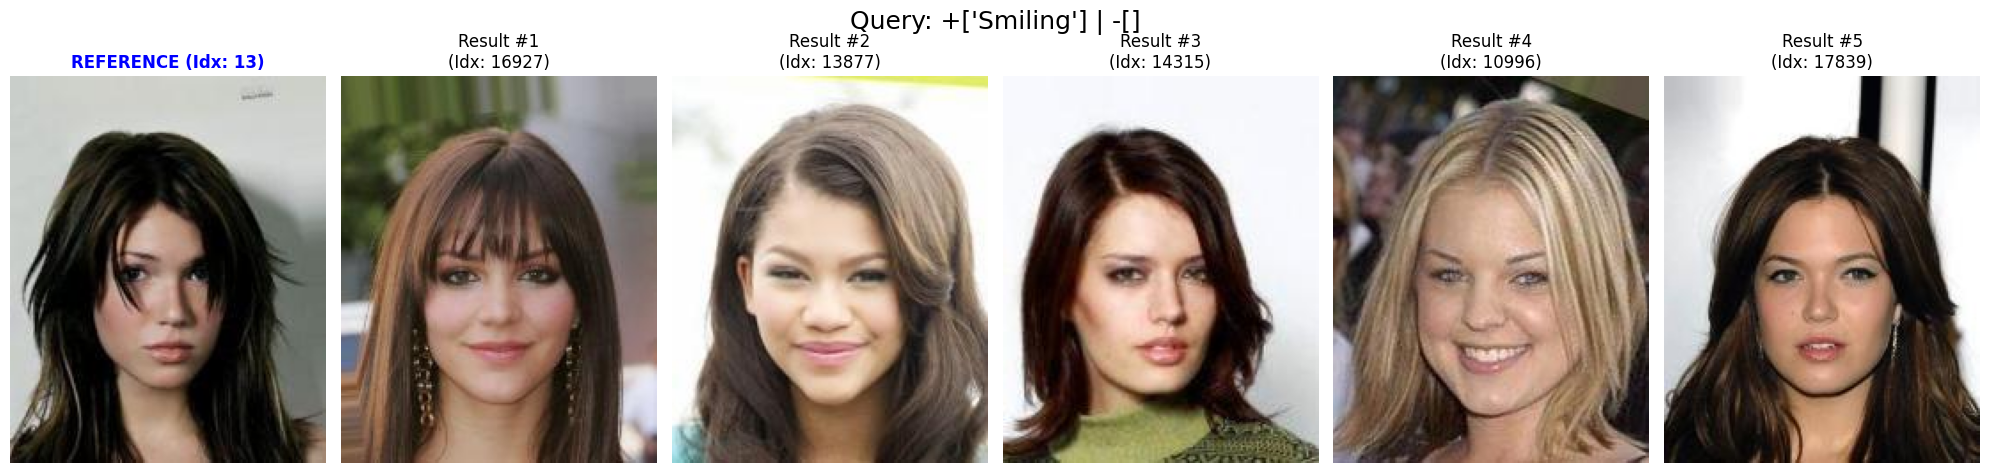

In [17]:
import torch.nn.functional as F

# Setting model on correct device
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# chose a number between 0 and 13
query_index = 0

query_entry = annotations[query_index]
query = query_entry["query"]
positive_conditions, negative_conditions = parse_query_string(query)

first_source_str, first_target_list = next(iter(query_entry["ground_truth"].items()))
reference_image_index = int(first_source_str)
gt_targets = [int(i) for i in first_target_list]

print(f"Searching for image {reference_image_index} with query: +{positive_conditions} and -{negative_conditions}")

top_k_indices, top_k_scores = baseline_zeroshot_retrieval(
    ref_idx=reference_image_index,
    positive_attrs=positive_conditions,
    negative_attrs=negative_conditions,
    db_embeddings=database_embeddings,
    processor=processor,
    model=model,
    device=device,
    top_k=5
)

print("\nTop 5 Images Retrieved:")
for i, (idx, score) in enumerate(zip(top_k_indices, top_k_scores)):
    print(f"{i+1}) Index: {idx} ") #| Similarity Score: {score:.4f}")


# evaluate_retival (retrieved_indices: list[int], ground_truth_indices: list[int],  k: int)
evaluation_res = evaluate_retrieval(top_k_indices, gt_targets, k=5)
print(f"\nevaluation_res@5: {evaluation_res}")

visualize_retrieval(
    ref_idx=reference_image_index,
    top_indices=top_k_indices,
    dataset=celeba,
    positive_attrs=positive_conditions,
    negative_attrs=negative_conditions
)

# Our Approach — Expressive Multimodal Conditioning

The assignment requires designing a **fusion module Φ** that accepts a reference image together
with multiple positive and negative textual conditions, and produces a composite query embedding.

To address the problem our idea was to define a pointer to the image to retrieve in this way:

pointer = normalize( α · v_ref  +  (1-α) · (a · µ_pos  −  b · µ_neg  +  c · µ_contr) )


where `µ_pos`, `µ_neg`, `µ_contr` are enriched text anchors (detailed below) and `a, b, c` are
learned scalar weights that control the relative contribution of each conditioning direction.

This formulation directly addresses the two core challenges from the assignment:
1. **Expressive multimodal conditioning** — positive and negative constraints interact explicitly
   via addition and subtraction in embedding space, with weights learned from data rather than
   assumed equal.
2. **Overcoming the naïve SVD bottleneck** — rather than concatenating all embeddings before
   SVD (CLAY's approach), we dynamically weight each semantic direction, giving the model
   direct, interpretable control over how conflicting conditions are balanced.

Why we choose to do it in this way?
Because there is a problem specifically with **negative conditions**:
CLIP subtraction alone is not sufficient to reliably remove a concept from the query.

Consider the query `− Black Hair`. Subtracting the embedding of *"black hair"* moves the
query vector away from that concept, but it does not specify *where* to move — the result
could land near *blonde*, *brown*, or *red hair* equally. Moreover, in CLIP space:

> **blonde hair ≠ not black hair**

These are distinct semantic directions. Simply adding the contrary (*"blonde hair"*) as a
replacement is also wrong, because the target may have any non-black hair color — we want
to remove the constraint, not impose a new one.








### Using Synonims and Antonyms

A single CLIP text embedding per attribute provides only a coarse, point estimate of the
semantic direction — it is sensitive to prompt phrasing and often misaligned with the visual
feature space. Inspired by the text expansion strategy in CLAY (Lim et al., CVPR 2026), we
instead build a **richer text anchor** for each attribute by aggregating multiple semantically
related prompts.

For each CelebA attribute we maintain two sets:
- **Synonyms** — alternative phrasings of the same concept (e.g. *"spectacles"*, *"glasses"*,
  *"eyewear"* for *Eyeglasses*)
- **Contraries** — expressions of the opposite concept (e.g. *"bare face"*, *"no glasses"*)

The mean embedding over these sets forms a more stable and semantically rich direction in
CLIP space than any single prompt alone.
.

From attributes (es + smile - glasses) to nice texts which will construct our text_subspace

In [18]:
def clean_attr(attr):
    return attr.replace("_", " ").lower()

In [19]:
def clean_query(pos, neg):
  for i in range(len(pos)):
    pos[i] = clean_attr(pos[i])

  for i in range(len(neg)):
    neg[i] = clean_attr(neg[i])

  return pos, neg

In [20]:
print(f"Query: {annotations[12]["query"]}\n")
pos, neg = parse_query_string(annotations[12]["query"])

pos, neg = clean_query(pos, neg)
print(f"Positive: {pos}")
print(f"Negative: {neg}")

Query: -Smiling, +Eyeglasses, +Wearing_Hat

Positive: ['eyeglasses', 'wearing hat']
Negative: ['smiling']


In [21]:
#importing base pool of synonyms and contraries
BASE_POOL_PATH = os.path.join(DRIVE_PROJECT_PATH, "Syn-Contr.json")

try:
   with open(BASE_POOL_PATH, "r") as f:
      BASE_POOL = json.load(f)

   print("File correctly loaded")
   print("-----------------------")
   for i, key in enumerate(BASE_POOL):
      print(f"{i}: {key}")
  #  print(BASE_POOL.keys())
except json.JSONDecodeError as e:
   print(f"Error: Failed to load BASE_POOL from '{BASE_POOL_PATH}'. The file is likely malformed JSON.")
   print(f"Details: {e}")
   print("Please check the content of your 'Syn-Contr.json' file for syntax errors.")
   BASE_POOL = {}
except FileNotFoundError:
   print(f"Error: BASE_POOL file not found at '{BASE_POOL_PATH}'. Please ensure the file exists.")
   BASE_POOL = {}

File correctly loaded
-----------------------
0: 5 o clock shadow
1: arched eyebrows
2: attractive
3: bags under eyes
4: bald
5: bangs
6: big lips
7: big nose
8: black hair
9: blond hair
10: blurry
11: brown hair
12: bushy eyebrows
13: chubby
14: double chin
15: eyeglasses
16: goatee
17: gray hair
18: heavy makeup
19: high cheekbones
20: male
21: mouth slightly open
22: mustache
23: narrow eyes
24: no beard
25: oval face
26: pale skin
27: pointy nose
28: receding hairline
29: rosy cheeks
30: sideburns
31: smiling
32: straight hair
33: wavy hair
34: wearing earrings
35: wearing hat
36: wearing lipstick
37: wearing necklace
38: wearing necktie
39: young


In [22]:
def get_expansion(attr):

    if attr in BASE_POOL:
        return BASE_POOL[attr]

    return {"synon": [attr], "contr": []}

An example:

In [23]:
exp = get_expansion("eyeglasses")

print("POS:", exp["synon"])
print("NEG:", exp["contr"])


POS: ['wearing glasses', 'eyeglasses', 'glasses', 'spectacles', 'eye glasses', 'optical glasses', 'framed glasses', 'thin glasses', 'thick glasses', 'round glasses']
NEG: ['no glasses', 'without glasses', 'no eyewear', 'no spectacles', 'bare eyes', 'uncovered eyes', 'visible eyes', 'eyes without glasses', 'face without glasses', 'no lenses']


We precomputed a pool of 10 synonyms and 10 contraries for each of the 40 CelebA attributes,
stored in `Syn-Contr.json`. However, not all prompts in the pool are equally informative for
CLIP — some are semantically distant from the visual concept. We therefore select the **top-3
most attribute-discriminative prompts** per set using CLIP itself as the judge.


In [24]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

best_expansions = {}

for attr in celeba.attr_names:

    if attr == "":
      continue

    cleaned_attr = clean_attr(attr)
    expansion = get_expansion(cleaned_attr)

    attr_emb = get_text_embedding(
        f"A picture of a person with {attr.lower}",
        processor, model, device
    )

    # ---- SYNON ----
    synon_scores = []
    for synon in expansion["synon"]:
        emb = get_text_embedding(f"A picture of a person with {synon}", processor, model, device)
        score = F.cosine_similarity(attr_emb, emb, dim=0)
        synon_scores.append((synon, score.item()))

    # ---- CONTR ----
    contr_scores = []
    for contr in expansion["contr"]:
        emb = get_text_embedding(f"A picture of a person with {contr}", processor, model, device)
        score = F.cosine_similarity(attr_emb, emb, dim=0)
        contr_scores.append((contr, score.item()))

    # ---- SELECT ----
    TOP_K = 3

    best_synon = sorted(synon_scores, key=lambda x: x[1], reverse=True)[:TOP_K]
    best_contr = sorted(contr_scores, key=lambda x: x[1])[:TOP_K]

    best_expansions[clean_attr(attr)] = {
        "synon": [x[0] for x in best_synon],
        "contr": [x[0] for x in best_contr]
    }

In [25]:
print(best_expansions.keys())
#last one is empty
print(f'Celeba attr length: {len(celeba.attr_names)-1}\nExpansion attr length: {len(best_expansions.keys())}')
print(best_expansions["young"])

dict_keys(['5 o clock shadow', 'arched eyebrows', 'attractive', 'bags under eyes', 'bald', 'bangs', 'big lips', 'big nose', 'black hair', 'blond hair', 'blurry', 'brown hair', 'bushy eyebrows', 'chubby', 'double chin', 'eyeglasses', 'goatee', 'gray hair', 'heavy makeup', 'high cheekbones', 'male', 'mouth slightly open', 'mustache', 'narrow eyes', 'no beard', 'oval face', 'pale skin', 'pointy nose', 'receding hairline', 'rosy cheeks', 'sideburns', 'smiling', 'straight hair', 'wavy hair', 'wearing earrings', 'wearing hat', 'wearing lipstick', 'wearing necklace', 'wearing necktie', 'young'])
Celeba attr length: 40
Expansion attr length: 40
{'synon': ['soft facial features', 'youthful face', 'firm skin'], 'contr': ['wrinkled skin', 'sagging skin', 'deep wrinkles']}


#### Building the Text Anchors µ_c

For each evaluation query we precompute three fixed text anchor vectors:

- `µ_pos` — mean CLIP embedding of the top-3 synonyms for each **positive** attribute
- `µ_neg` — mean CLIP embedding of the top-3 synonyms for each **negative** attribute
  (the direction to move *away from*)
- `µ_contr` — mean CLIP embedding of the top-3 contraries for each **negative** attribute
  (the direction to move *toward*)

These vectors are unit-normalized and remain **frozen** throughout training — only the scalar
weights `(a, b, c)` are learned.


In [26]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

annotations_mean = {}

for ann in annotations:

  query_text = ann["query"]
  print("Working on query: ", query_text)

  # Parse the query string
  pos_attrs, neg_attrs = parse_query_string(query_text)

  # Clean the parsed attributes
  pos_attrs_cleaned, neg_attrs_cleaned = clean_query(pos_attrs, neg_attrs)

  pos_sinonimi_emb_mean = []

  neg_sinonimi_emb_mean = []
  neg_contrari_emb_mean = []


  for attr in pos_attrs_cleaned:
      expansion = best_expansions[attr]

      current_attr_embeddings = []
      # Add embeddings of positive expanded terms
      for synon in expansion["synon"]:
          current_attr_embeddings.append(get_text_embedding(f"A picture of a person with {synon}", processor, model, device))

      pos_sinonimi_emb_mean.append(torch.mean(torch.stack(current_attr_embeddings), dim=0))


  for attr in neg_attrs_cleaned:
      expansion = best_expansions[attr] # Changed from get_expansion(attr) to best_expansions[attr]

      current_syn_emb = []
      current_contr_emb = []
      # Add embeddings of negative expanded terms

      # synonyms
      for synon in expansion["synon"]:
          current_syn_emb.append(get_text_embedding(f"A picture of a person with {synon}", processor, model, device))

      neg_sinonimi_emb_mean.append(torch.mean(torch.stack(current_syn_emb), dim=0))

      # antonyms
      for contr in expansion["contr"]:
          current_contr_emb.append(get_text_embedding(f"A picture of a person with {contr}", processor, model, device))

      neg_contrari_emb_mean.append(torch.mean(torch.stack(current_contr_emb), dim=0))


  pos_sinonimi_emb_mean = (torch.zeros(model.config.text_config.hidden_size, device=device) if not pos_sinonimi_emb_mean else pos_sinonimi_emb_mean)
  neg_sinonimi_emb_mean = (torch.zeros(model.config.text_config.hidden_size, device=device) if not neg_sinonimi_emb_mean else neg_sinonimi_emb_mean)
  neg_contrari_emb_mean = (torch.zeros(model.config.text_config.hidden_size, device=device) if not neg_contrari_emb_mean else neg_contrari_emb_mean)


  annotations_mean[query_text] = {
      "pos_sinonimi_emb_mean": pos_sinonimi_emb_mean,
      "neg_sinonimi_emb_mean": neg_sinonimi_emb_mean,
      "neg_contrari_emb_mean": neg_contrari_emb_mean
  }

print("query: ", query_text)
# Stack the list of average vectors into a single tensor to be able to use .shape
# Ensure there are embeddings to stack before calling torch.stack
if pos_sinonimi_emb_mean:
    pos_sinonimi_emb_tensor = torch.stack(pos_sinonimi_emb_mean)
    print("\nShape della lista di medie per i sinonimi del positivo: ",pos_sinonimi_emb_tensor.shape)
else:
    print("\nNo positive synonym embeddings to stack for the last query.")

Working on query:  +Smiling
Working on query:  +Eyeglasses
Working on query:  -Heavy_Makeup
Working on query:  +Male
Working on query:  -Young
Working on query:  +Blond_Hair
Working on query:  +Mustache
Working on query:  -Young
Working on query:  +Eyeglasses, +Smiling
Working on query:  +Black_Hair, -Wavy_Hair
Working on query:  -Male, -Mustache
Working on query:  +Chubby, -Young
Working on query:  -Smiling, +Eyeglasses, +Wearing_Hat
Working on query:  +Wearing_Lipstick, -Heavy_Makeup, +Smiling
query:  +Wearing_Lipstick, -Heavy_Makeup, +Smiling

Shape della lista di medie per i sinonimi del positivo:  torch.Size([2, 512])


In [27]:
#we now filter the synonims based on CLIP preferences
def get_mean_emb(embeddings, config, device):

  if isinstance(embeddings, list):
      mean = torch.mean(torch.stack(embeddings), dim=0)
  elif embeddings is not None:
      mean = torch.mean(embeddings, dim=0)

  return mean

# First Validation — Single Query Proof of Concept

Before scaling to the full benchmark, we validate the core idea on a single controlled query:
`+ Chubby & - Young`. The goal is to confirm that learned scalar weights `(a, b, c)` improve
over the equal-weight baseline before adding the complexity of multi-query training.

### Loss Function — Hard-Negative Margin Ranking Loss

A softmax/cross-entropy loss is unsuitable here: the database has 19,962 entries and each
query admits multiple valid ground-truth targets, so treating retrieval as single-class
classification would be both computationally expensive and semantically wrong.

We instead use a **margin-based ranking loss** that enforces a relative ordering — correct
images must score above incorrect ones by at least a fixed gap `margin`:



In [28]:
def loss_fn2(scores, gt_indices, margin=0.2):
    '''
    Margin-based loss that pushes positive scores above hard negatives by a fixed margin.
    Uses top-ranked negatives to focus learning on the most confusing mistakes.
    '''
    # Ensure gt_indices is not empty.
    if not gt_indices:
        return torch.tensor(0.0, device=scores.device, requires_grad=True)

    # Ensure gt_indices in bounds of scores
    valid_gt_indices = [idx for idx in gt_indices if idx < scores.size(0)]

    if not valid_gt_indices:
        return torch.tensor(0.0, device=scores.device, requires_grad=True)

    # Positive scores for gt, negative for others
    pos_scores = scores[valid_gt_indices]
    mask = torch.ones_like(scores, dtype=torch.bool)
    mask[valid_gt_indices] = False
    neg_scores = scores[mask]

    # If there are no negative samples, return a zero loss.
    if len(neg_scores) == 0:
        return torch.tensor(0.0, device=scores.device, requires_grad=True)

    k = int(len(neg_scores) / 2)
    # Ensure k is at least 1, to prevent issues with topk(0) if neg_scores is not empty
    k = max(1, k)

    # Hard negatives are wrong images with high score
    hard_neg_values = neg_scores.topk(k).values
    mean_hard_neg = hard_neg_values.mean()

    individual_losses = torch.relu(margin - pos_scores + mean_hard_neg)

    # Take the mean of individual losses to get a single scalar loss
    loss = torch.mean(individual_losses)

    return loss

The indices of the ground truth are not in score order. By setting them in score order we would be able to use **ranking loss** for our training. Notice that we can only use this order as soft weight as otherwise we would impose that an image is better than another, while this might not be true. The right solution is to order the ground-truth in order to **suggest** a solution, without imposing anything.
In this way we always project on the correct result by preserving the reference identity in retrieval.

In [29]:
def annotations_ordering(annotations, database_embeddings, device="cpu"):
    """
    Orders the ground truth target images for each reference image in the annotations
    based on their cosine similarity to the reference image.
    """
    annotations_ordered = []

    # Ensure database embeddings are on the correct device
    db_embs = database_embeddings.to(device)

    # Normalize the database once for correct cosine similarity (dot product of normalized vectors)
    db_embs_norm = db_embs / db_embs.norm(dim=-1, keepdim=True).clamp(min=1e-8)

    for ann in annotations:
        query = ann["query"]
        ground_truth = ann["ground_truth"]

        new_gt = {}

        for ref_idx_str, gt_indices in ground_truth.items():
            ref_idx = int(ref_idx_str)

            # Get the normalized reference vector
            ref_vec = db_embs_norm[ref_idx]

            # Calculate cosine similarities against all database images
            # (Since vectors are normalized, dot product == cosine similarity)
            scores = ref_vec @ db_embs_norm.T

            # Extract scores only for the ground truth target indices
            gt_scores = scores[gt_indices]

            # Sort the ground truth indices by their similarity scores (highest first)
            sorted_idx = torch.argsort(gt_scores, descending=True)

            # Reorder the target list based on the sorted indices
            ordered_gt = [gt_indices[i.item()] for i in sorted_idx]

            # Assign the ordered list back to the reference key
            new_gt[ref_idx_str] = ordered_gt

        # Append correctly without the extra nested dictionary
        annotations_ordered.append({
            "query": query,
            "ground_truth": new_gt
        })

    return annotations_ordered

In [30]:
#checking if file alredy exists

ANN_PATH = os.path.join(DRIVE_PROJECT_PATH, "ordered_ann.js")

if os.path.exists(ANN_PATH):

  print("File found, loading ordered annotations...")
  with open(ANN_PATH, "r") as f:
    ordered_annotations = json.load(f)
  print("Ordered annotations loaded successfully")

else:
  print("File not found, ordering annotations and generating new file")
  ordered_annotations = annotations_ordering(annotations, database_embeddings)
  print("Ordered annotations generated, saving the file")
  with open(ANN_PATH, "w") as f:
        json.dump(ordered_annotations, f, indent=4)

  print("File saved successfully")


File found, loading ordered annotations...
Ordered annotations loaded successfully


### Experimental Setup

We isolate query `+ Chubby & - Young` from the benchmark and split its reference images
**80% training / 20% test**. Note that this uses the evaluation JSON for training — a
methodological simplification acceptable only for this proof-of-concept step. The full
multi-query optimizer (next section) uses attribute-based training pairs instead.


In [31]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Fixed query embeddings
emb_pos_condition = get_text_embedding("Chubby", processor, model, device).to(device).squeeze()
emb_neg_condition = get_text_embedding("Young", processor, model, device).to(device).squeeze()
emb_cont_condition = get_text_embedding("Old", processor, model, device).to(device).squeeze()

# Global normalization for similarity
db_embs = database_embeddings.to(device)
db_embs_norm = db_embs / db_embs.norm(dim=-1, keepdim=True).clamp(min=1e-8)

#Choosing one query
TARGET_QUERY = "+Chubby, -Young"
filtered_annotations = [ann for ann in annotations if ann["query"] == TARGET_QUERY]
print(f"Found {len(filtered_annotations)} annotations corresponding to query: '{TARGET_QUERY}'")

#splitting ground truth
import random

if len(filtered_annotations) > 0:
    base_annotation = filtered_annotations[0]
    full_ground_truth = base_annotation["ground_truth"]

    gt_items = list(full_ground_truth.items())
    split_idx = int(len(gt_items) * 0.8)

    # Forcing at least one element in training
    if split_idx == 0 and len(gt_items) > 0:
        split_idx = 1

    train_items = gt_items[:split_idx]
    test_items = gt_items[split_idx:]

    train_ground_truth = dict(train_items)
    test_ground_truth = dict(test_items)

    # Creating dictionaries
    train_annotations = [{
        "query": TARGET_QUERY,
        "ground_truth": train_ground_truth
    }]

    test_annotations = [{
        "query": TARGET_QUERY,
        "ground_truth": test_ground_truth
    }]

    print(f"Split completed for query '{TARGET_QUERY}':")
    print(f"  - Reference images for TRAINING: {len(train_ground_truth)}")
    print(f"  - Reference images for TESTING: {len(test_ground_truth)}")

else:
    print(f"WAENING: No annotations founded for query: '{TARGET_QUERY}'")


Found 1 annotations corresponding to query: '+Chubby, -Young'
Split completed for query '+Chubby, -Young':
  - Reference images for TRAINING: 467
  - Reference images for TESTING: 117


Function for qualitative inference with fixed scalar weights (a, b, c, alpha).

In [32]:
def parameter_image_retrieval(query, a, b, c, alpha, db_embeddings, processor, model, device, top_k=5):
    """
    Implementing baseline
    """

    query_text = query["query"]

    query_emb = annotations_mean[query_text]
    ref_idx_str, first_target_list = next(iter(query["ground_truth"].items()))
    ref_idx = int(ref_idx_str)

    pos_attrs, neg_attrs = parse_query_string(query_text)

    model.eval()

    v_ref = db_embeddings[ref_idx].to(device)

    t_pos_attr = get_mean_emb(query_emb['pos_sinonimi_emb_mean'], model.config, device)
    t_neg_attr = get_mean_emb(query_emb['neg_sinonimi_emb_mean'], model.config, device)
    t_cont_attr = get_mean_emb(query_emb['neg_contrari_emb_mean'], model.config, device)

    query_embedding = alpha*v_ref + (1-alpha)*(a*t_pos_attr - b*t_neg_attr + c*t_cont_attr)

    # FInal query normalization
    query_embedding = F.normalize(query_embedding.unsqueeze(0), p=2, dim=-1)

    # Computing similarity
    db_embeddings = db_embeddings.to(device)
    similarities = torch.matmul(db_embeddings, query_embedding.T).squeeze()
    similarities[ref_idx] = -1.0

    # We take the top-k
    top_scores, top_indices = torch.topk(similarities, top_k)

    visualize_retrieval(
        ref_idx=ref_idx,
        top_indices=top_indices,
        dataset=celeba,
        positive_attrs=pos_attrs,
        negative_attrs=neg_attrs
    )


    return top_indices.cpu().numpy(), top_scores.cpu().detach().numpy()

Optimization with Adam

In [ ]:
#defining fixed parameter
base = torch.nn.Parameter(torch.tensor(0.7, device=device))
delta_b = torch.nn.Parameter(torch.tensor(1.0, device=device))
delta_c = torch.nn.Parameter(torch.tensor(0.5, device=device))


# Passing parameters to Adam
optimizer = torch.optim.Adam([base, delta_b, delta_c], lr=1e-2)

NUM_EPOCHS = 20

#Training loop
for epoch in range(NUM_EPOCHS):
    epoch_loss = 0.0
    samples_count = 0

    for ann in train_annotations:
        for ref_idx_str, gt_indices in ann["ground_truth"].items():
            ref_idx = int(ref_idx_str)
            if not gt_indices:
                continue

            ref_image_emb = db_embs_norm[ref_idx].unsqueeze(0)

            # Applying positivity constraint
            a_pos = F.softplus(base)
            b_pos = F.softplus(base + delta_b)

            # SIGMOID to have c < a
            c_ratio = torch.sigmoid(delta_c)
            c_pos = a_pos * c_ratio

            emb = annotations_mean[ann["query"]]

            pos_emb_mean = get_mean_emb(emb['pos_sinonimi_emb_mean'], model.config, device)
            neg_emb_mean = get_mean_emb(emb['neg_sinonimi_emb_mean'], model.config, device)
            cont_emb_mean = get_mean_emb(emb['neg_contrari_emb_mean'], model.config, device)

            pointer = ref_image_emb + ((a_pos * pos_emb_mean) - (b_pos * neg_emb_mean) + (c_pos * cont_emb_mean))

            pointer_norm = F.normalize(pointer, p=2, dim=-1)

            scores = (pointer_norm @ db_embs_norm.T).squeeze(0)
            loss = loss_fn2(scores, gt_indices, margin=0.2)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            samples_count += 1

    if samples_count > 0:
        print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] -> Average Loss: {epoch_loss/samples_count:.4f}")
        print(f"Fixed values -> a: {a_pos.item():.3f} | b: {b_pos.item():.3f} | c: {c_pos.item():.3f} ")
        print(f"Gradients a: {base.grad.item():.3f} | b: {delta_b.grad.item():.3f} | c: {delta_c.grad.item():.3f} ")
        print("-" * 50)

Epoch [1/20] -> Average Loss: 0.2114
Fixed values -> a: 3.164 | b: 6.117 | c: 1.324 
Gradients a: -0.004 | b: -0.002 | c: -0.002 
--------------------------------------------------
Epoch [2/20] -> Average Loss: 0.2023
Fixed values -> a: 5.111 | b: 8.681 | c: 2.340 
Gradients a: -0.003 | b: -0.000 | c: -0.004 
--------------------------------------------------
Epoch [3/20] -> Average Loss: 0.1986
Fixed values -> a: 6.794 | b: 10.843 | c: 3.498 
Gradients a: -0.002 | b: -0.001 | c: -0.003 
--------------------------------------------------
Epoch [4/20] -> Average Loss: 0.1967
Fixed values -> a: 7.986 | b: 12.561 | c: 4.078 
Gradients a: -0.001 | b: -0.001 | c: -0.003 
--------------------------------------------------
Epoch [5/20] -> Average Loss: 0.1956
Fixed values -> a: 8.964 | b: 14.032 | c: 4.551 
Gradients a: -0.001 | b: -0.001 | c: -0.003 
--------------------------------------------------
Epoch [6/20] -> Average Loss: 0.1948
Fixed values -> a: 9.811 | b: 15.346 | c: 5.000 
Gradie

for the evaluation of the results give by the optimizer

In [33]:
import numpy as np

def evaluate_fixed_params_retrieval(
    test_annotations,
    db_embs_norm,
    emb_pos,
    emb_neg,
    emb_cont,
    evaluation_results,
    a_fixed,
    b_fixed,
    c_fixed,
    alpha,
    k_eval=10
):
    """
    Retrieval with FIXED weights (a, b, c, alpha) on the whole test set,
    computes average metrics and compares them with the baseline zero-shot.
    """

    EVAL_K_VALUES = [1, 5, k_eval]

    fixed_recalls_dict = {f"Recall@{k}": [] for k in EVAL_K_VALUES}
    fixed_precisions_dict = {f"Precision@{k}": [] for k in EVAL_K_VALUES}

    print(f"Starting global testing (Fixed Parameter) on {len(test_annotations[0]['ground_truth'])} reference images...")
    print("-" * 75)

    # No gradients for testing
    with torch.no_grad():
        for ann in test_annotations:
            for ref_idx_str, gt_indices in ann["ground_truth"].items():
                ref_idx = int(ref_idx_str)

                if not gt_indices:
                    continue

                # Loading ref embedding
                v_ref = db_embs_norm[ref_idx].unsqueeze(0)

                # Pointer construction
                pointer = alpha*v_ref + (1-alpha)*((a_fixed * emb_pos) - (b_fixed * emb_neg) + (c_fixed * emb_cont))
                pointer_norm = F.normalize(pointer, p=2, dim=-1)

                # Computing total similarity
                similarities = (pointer_norm @ db_embs_norm.T).squeeze(0)
                similarities[ref_idx] = -1.0  #No reference

                # Extracting Top-K (max k_eval) predicted indices
                _, top_indices = torch.topk(similarities, k=max(EVAL_K_VALUES))
                retrieved_indices = top_indices.cpu().tolist()

                # Computing metrics for all K_VALUES
                for k in EVAL_K_VALUES:
                    res = evaluate_retrieval(retrieved_indices, gt_indices, k=k)
                    fixed_recalls_dict[f"Recall@{k}"].append(res[f"Recall@{k}"])
                    fixed_precisions_dict[f"Precision@{k}"].append(res[f"Precision@{k}"])


    # Computing final means
    mean_fixed_metrics = {
        f"Recall@{k}": np.mean(fixed_recalls_dict[f"Recall@{k}"]) for k in EVAL_K_VALUES
    }
    mean_fixed_metrics.update({
        f"Precision@{k}": np.mean(fixed_precisions_dict[f"Precision@{k}"]) for k in EVAL_K_VALUES
    })

    mean_base_metrics = {
        f"Recall@{k}": evaluation_results[TARGET_QUERY].get(f"Recall@{k}", 0.0) for k in EVAL_K_VALUES
    }
    mean_base_metrics.update({
        f"Precision@{k}": evaluation_results[TARGET_QUERY].get(f"Precision@{k}", 0.0) for k in EVAL_K_VALUES
    })


    # Comparative table
    rows = []
    for k in EVAL_K_VALUES:
        for metric in ["Recall", "Precision"]:
            key = f"{metric}@{k}"
            baseline_val = mean_base_metrics[key]
            fixed_val    = mean_fixed_metrics[key]
            diff         = fixed_val - baseline_val
            rows.append({
                "Metric":              key,
                "Baseline":     baseline_val,
                "Optimizer":          fixed_val,
                "Gain":             diff,
            })

    report_df = pd.DataFrame(rows).set_index("Metric")

    formatted_df = pd.DataFrame({
        "Baseline": report_df["Baseline"].map(lambda x: f"{x*100:.2f} %"),
        "Optimizer":      report_df["Optimizer"].map(lambda x: f"{x*100:.2f} %"),
        "Gain":         report_df["Gain"].map(lambda x: f"{x*100:+.2f} %"),
    }, index=report_df.index)

    print(f"\nQuery: {TARGET_QUERY}  |  a={a_fixed:.3f}  b={b_fixed:.3f}  c={c_fixed:.3f}  alpha={alpha:.3f}")
    display(formatted_df)

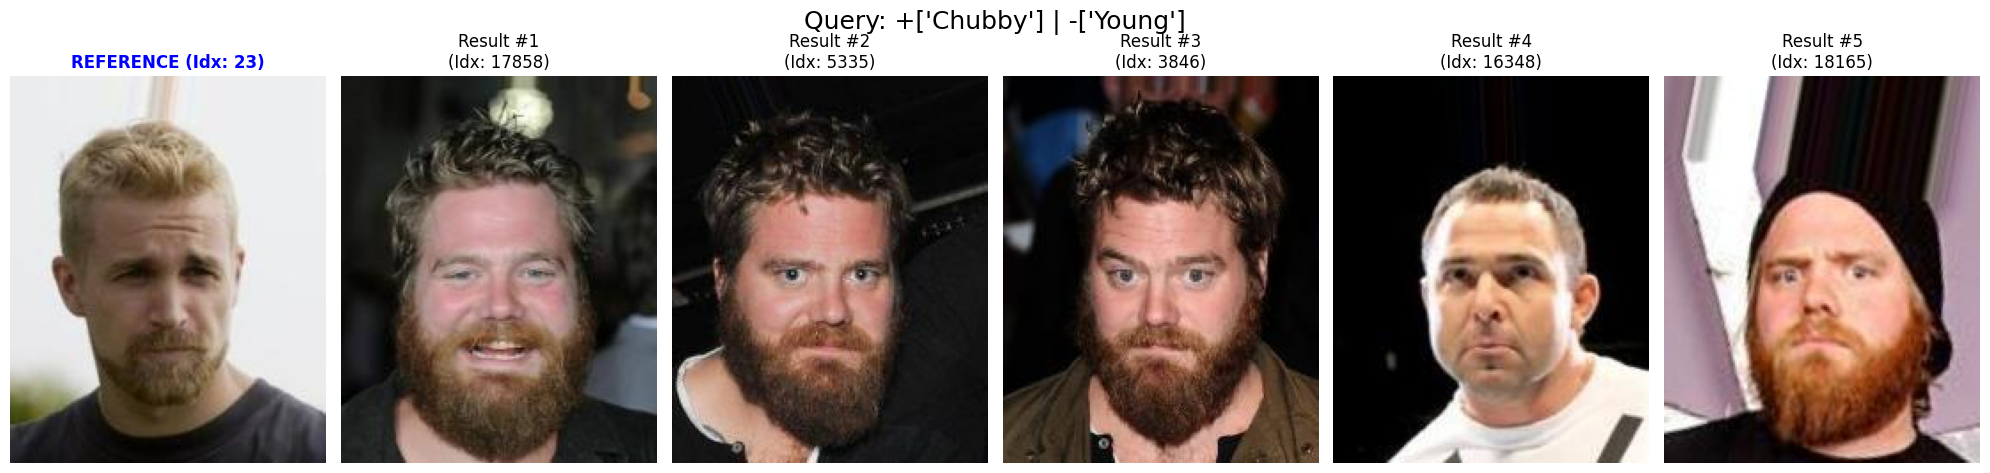

Starting global testing (Fixed Parameter) on 117 reference images...
---------------------------------------------------------------------------

Query: +Chubby, -Young  |  a=16.250  b=26.810  c=9.764  alpha=0.700


,Baseline,Optimizer,Gain
Metric,,,
Recall@1,0.34 %,3.42 %,+3.08 %
Precision@1,0.34 %,3.42 %,+3.08 %
Recall@5,1.20 %,5.13 %,+3.93 %
Precision@5,0.27 %,1.03 %,+0.75 %
Recall@10,2.40 %,9.40 %,+7.00 %
Precision@10,0.26 %,1.03 %,+0.77 %


In [ ]:
#Checking results with new parameter
alpha = 0.7#big alpha because training is direct and coefficient are well computed, no need to extremely amplify them
query_emb = annotations_mean[train_annotations[0]["query"]]
emb_pos_condition = get_mean_emb(query_emb['pos_sinonimi_emb_mean'], model.config, device)
emb_neg_condition = get_mean_emb(query_emb['neg_sinonimi_emb_mean'], model.config, device)
emb_cont_condition = get_mean_emb(query_emb['neg_contrari_emb_mean'], model.config, device)

parameter_image_retrieval(train_annotations[0], a_pos, b_pos, c_pos,alpha,
                          database_embeddings, processor, model, device)

# Extracting final values
with torch.no_grad():
    #a_final = F.softplus(a_pos).item()
    #b_final = F.softplus(b_pos).item()
    #c_final = F.softplus(c_pos).item()
    a_final = a_pos.item()
    b_final = b_pos.item()
    c_final = c_pos.item()

fixed_results = evaluate_fixed_params_retrieval(
    test_annotations=test_annotations,
    db_embs_norm=db_embs_norm,
    emb_pos=emb_pos_condition,
    emb_neg=emb_neg_condition,
    emb_cont=emb_cont_condition,
    evaluation_results=evaluation_results,
    a_fixed=a_final,
    b_fixed=b_final,
    c_fixed=c_final,
    alpha=alpha,
    #temperature = 1,
    k_eval=10

)



We reached better results with respect to the baseline. Now, since our idea is validated we try to apply a similar approach (optimization) to all the queries.

# Optimizer on all queries


The key methodological change from the previous section is the **training data source**.
Instead of using the Using the evaluation JSON, we generate training
pairs directly from CelebA attribute annotations, reserving the evaluation JSON exclusively
for testing.


In [34]:
# Attribute-Based Training

# celeba.attr is a (N, 40) LongTensor of 0/1 binary attribute labels
attr_matrix = celeba.attr.float()  # (N, 40)

# Build name → column-index mapping; skip the empty trailing attr name
attr_name_to_idx = {
    clean_attr(name): i
    for i, name in enumerate(celeba.attr_names)
    if name != ""
}

# Only use attributes that have pre-built projection matrices (CLAY pipeline)
trainable_attrs = [name for name in attr_name_to_idx] #if name in projection_matrices

print(f"Attribute matrix : {attr_matrix.shape}")
print(f"Trainable attrs  : {len(trainable_attrs)} / {len(attr_name_to_idx)}")
print(f"Examples         : {trainable_attrs[:5]}")

print(f"first image, first attribute: {trainable_attrs[0]}, value: {attr_matrix[0][0]} ")


Attribute matrix : torch.Size([19962, 40])
Trainable attrs  : 40 / 40
Examples         : ['5 o clock shadow', 'arched eyebrows', 'attractive', 'bags under eyes', 'bald']
first image, first attribute: 5 o clock shadow, value: 0.0 


In [35]:
def get_attribute_ground_truth(ref_idx, pos_attr_indices, neg_attr_indices,
                               attr_matrix, max_hamming=2):
    """
    Ground-truth from CelebA attributes (mirrors evaluation JSON criterion).
    Valid target: satisfies all query constraints AND Hamming <= max_hamming on remaining attrs.
    """
    ref_attrs = attr_matrix[ref_idx]
    N         = attr_matrix.shape[0]
    query_cols = set(pos_attr_indices + neg_attr_indices)

    satisfies = torch.ones(N, dtype=torch.bool)
    for i in pos_attr_indices:
        satisfies &= (attr_matrix[:, i] == 1)
    for i in neg_attr_indices:
        satisfies &= (attr_matrix[:, i] == 0)

    non_query_mask = torch.tensor([j not in query_cols for j in range(attr_matrix.shape[1])])
    ref_rest = ref_attrs[non_query_mask].unsqueeze(0)
    db_rest  = attr_matrix[:, non_query_mask]
    hamming  = (db_rest != ref_rest).float().sum(dim=1)

    valid = satisfies & (hamming <= max_hamming)
    valid[ref_idx] = False

    valid_indices = valid.nonzero(as_tuple=False).squeeze(-1)
    if len(valid_indices) == 0:
        return []
    sorted_gt = valid_indices[hamming[valid_indices].argsort()]
    return sorted_gt.tolist()


### Attribute-Based Training Pairs

For each of the 14 evaluation queries, we sample `N_SAMPLES_PER_QUERY = 200` reference
images from the full 19,962-image test set. For each reference, the ground truth is computed
on-the-fly from CelebA binary attribute labels using the **same Hamming ≤ 2 criterion** as
the evaluation JSON:

- a candidate target must strictly satisfy all positive/negative constraints of the query
- its remaining (non-queried) attributes must differ from the reference by at most 2 positions

This mirrors the evaluation protocol exactly, ensuring that what the optimizer learns to
optimize is directly aligned with what will be measured at test time.

In [36]:
#Generate training pairs from the 14 predefined assignment queries.
# For each query, sample N_SAMPLES_PER_QUERY reference images from the full 20k database.
# Ground truth is derived from CelebA attribute annotations — NOT from the evaluation JSON
# (that is reserved for testing only).

N_SAMPLES_PER_QUERY = 200   # ref images to try per query
MAX_HAMMING          = 2    # mirrors the evaluation JSON criterion
random.seed(42)

N_images = len(celeba)

#Use the 14 predefined evaluation queries as training queries
query_strings = [ann["query"] for ann in annotations]
print(f"Using {len(query_strings)} training queries:")

for q in query_strings: print(f"  {q}")
print()

train_pairs = []

for query_str in query_strings:
    pos_names_raw, neg_names_raw = parse_query_string(query_str)
    pos_names, neg_names = clean_query(list(pos_names_raw), list(neg_names_raw))

    # Filter to attrs that exist in both the attribute index and projection_matrices
    pos_names = [a for a in pos_names if a in attr_name_to_idx]
    neg_names = [a for a in neg_names if a in attr_name_to_idx]

    if not pos_names and not neg_names:
        print(f"  WARNING: no trainable attrs for '{query_str}' — skipping")
        continue

    pos_indices = [attr_name_to_idx[a] for a in pos_names]
    neg_indices = [attr_name_to_idx[a] for a in neg_names]

    ref_candidates = random.sample(range(N_images), min(N_SAMPLES_PER_QUERY, N_images))
    valid_count = 0

    for ref_idx in ref_candidates:
        gt = get_attribute_ground_truth(
            ref_idx, pos_indices, neg_indices, attr_matrix, max_hamming=MAX_HAMMING
        )
        if not gt:
            continue
        train_pairs.append({
            "ref_idx":   ref_idx,
            "pos_attrs": pos_names,
            "neg_attrs": neg_names,
            "gt_indices": gt,
            "query":     query_str,
        })
        valid_count += 1

    print(f"  '{query_str}' → {valid_count}/{N_SAMPLES_PER_QUERY} valid pairs")

print(f"\nTotal training pairs: {len(train_pairs)}")
gt_sizes = [len(p['gt_indices']) for p in train_pairs]
print(f"GT size  — min: {min(gt_sizes)}, max: {max(gt_sizes)}, "
      f"mean: {sum(gt_sizes)/len(gt_sizes):.1f}")

Using 14 training queries:
  +Smiling
  +Eyeglasses
  -Heavy_Makeup
  +Male
  -Young
  +Blond_Hair
  +Mustache
  -Young
  +Eyeglasses, +Smiling
  +Black_Hair, -Wavy_Hair
  -Male, -Mustache
  +Chubby, -Young
  -Smiling, +Eyeglasses, +Wearing_Hat
  +Wearing_Lipstick, -Heavy_Makeup, +Smiling

  '+Smiling' → 170/200 valid pairs
  '+Eyeglasses' → 67/200 valid pairs
  '-Heavy_Makeup' → 170/200 valid pairs
  '+Male' → 113/200 valid pairs
  '-Young' → 151/200 valid pairs
  '+Blond_Hair' → 120/200 valid pairs
  '+Mustache' → 31/200 valid pairs
  '-Young' → 147/200 valid pairs
  '+Eyeglasses, +Smiling' → 50/200 valid pairs
  '+Black_Hair, -Wavy_Hair' → 155/200 valid pairs
  '-Male, -Mustache' → 155/200 valid pairs
  '+Chubby, -Young' → 57/200 valid pairs
  '-Smiling, +Eyeglasses, +Wearing_Hat' → 30/200 valid pairs
  '+Wearing_Lipstick, -Heavy_Makeup, +Smiling' → 101/200 valid pairs

Total training pairs: 1517
GT size  — min: 1, max: 676, mean: 21.6


Each line reports how many of the 200 sampled reference images produced at least one valid
ground-truth target. Queries with visually rare positive attributes (e.g. `+ Mustache`) yield
fewer valid pairs because fewer database images satisfy the constraint — this is an inherent
property of the CelebA attribute distribution, not an implementation issue.


### Optimizer

Scalar `(a, b, c)` are optimized on attribute-based ground truth.

Pointer formula:

```
pointer = alpha * ref_emb + (1-alpha) * (a * pos_emb - b * neg_emb + c * cont_emb)
```


In [37]:
# Pointer optimizer (NO CLAY) trained on attribute-based training pairs.
# Same base/delta_b/delta_c parameterisation as the CLAY optimizer but uses
# annotations_mean text embeddings directly — no projection matrices or rotation.

#small alpha because coefficient are generalized, we need to amplify them in order to achieve good result
ALPHA_FIXED = 0.3

patience = 3
prev_loss = 0.0

db_embs_norm_ptr = F.normalize(database_embeddings, p=2, dim=-1).to(device)

base_ptr    = torch.nn.Parameter(torch.tensor(1.0,  device=device))
delta_b_ptr = torch.nn.Parameter(torch.tensor(1.0,  device=device))
delta_c_ptr = torch.nn.Parameter(torch.tensor(-1.0, device=device))

optimizer_ptr   = torch.optim.Adam([base_ptr, delta_b_ptr, delta_c_ptr], lr=1e-2)
NUM_EPOCHS_PTR  = 5

for epoch in range(NUM_EPOCHS_PTR):
    epoch_loss, samples_count = 0.0, 0
    shuffled = train_pairs.copy()
    random.shuffle(shuffled)

    for pair in shuffled:
        ref_idx    = pair["ref_idx"]
        query_str  = pair["query"]
        gt_indices = [i for i in pair["gt_indices"] if i < len(db_embs_norm_ptr)]
        if not gt_indices:
            continue

        ref_image_emb = db_embs_norm_ptr[ref_idx].unsqueeze(0)

        a_pos   = F.softplus(base_ptr)
        b_pos   = F.softplus(base_ptr + delta_b_ptr)
        c_pos   = a_pos * torch.sigmoid(delta_c_ptr)

        emb           = annotations_mean[query_str]
        pos_emb_mean  = get_mean_emb(emb['pos_sinonimi_emb_mean'],  model.config, device)
        neg_emb_mean  = get_mean_emb(emb['neg_sinonimi_emb_mean'],  model.config, device)
        cont_emb_mean = get_mean_emb(emb['neg_contrari_emb_mean'],  model.config, device)

        #pointer      = (ref_image_emb +  (a_pos * pos_emb_mean   - b_pos * neg_emb_mean + c_pos * cont_emb_mean))

        pointer = (ALPHA_FIXED * ref_image_emb
           + (1 - ALPHA_FIXED) * (a_pos * pos_emb_mean
                                  - b_pos * neg_emb_mean
                                  + c_pos * cont_emb_mean))

        pointer_norm = F.normalize(pointer, p=2, dim=-1)

        scores = (pointer_norm @ db_embs_norm_ptr.T).squeeze(0)
        loss   = loss_fn2(scores, gt_indices, margin=0.2)

        optimizer_ptr.zero_grad()
        loss.backward()
        optimizer_ptr.step()

        epoch_loss    += loss.item()
        samples_count += 1

    if samples_count > 0:
        a_v = F.softplus(base_ptr).item()
        b_v = F.softplus(base_ptr + delta_b_ptr).item()
        c_v = (F.softplus(base_ptr) * torch.sigmoid(delta_c_ptr)).item()
        print(f"Epoch [{epoch+1}/{NUM_EPOCHS_PTR}]  loss={epoch_loss/samples_count:.4f}  "
              f"a={a_v:.3f}  b={b_v:.3f}  c={c_v:.3f} ")
        print(f"Gradients → a: {base_ptr.grad.item():.3f}  b: {delta_b_ptr.grad.item():.3f}  c: {delta_c_ptr.grad.item():.3f}  ")

    if (prev_loss - epoch_loss) < 1e-5:
        print("Loss difference: ", epoch_loss -prev_loss)
        patience -= 1
        if patience == 0:
            break
    else:
        patience = 3

    prev_loss = epoch_loss

with torch.no_grad():
    a_ptr = F.softplus(base_ptr).item()
    b_ptr = F.softplus(base_ptr + delta_b_ptr).item()
    c_ptr = (F.softplus(base_ptr) * torch.sigmoid(delta_c_ptr)).item()

print(f"\nFinal — a={a_ptr:.4f}  b={b_ptr:.4f}  c={c_ptr:.4f} ")

Epoch [1/5]  loss=0.1726  a=0.293  b=0.387  c=0.142 
Gradients → a: -0.006  b: -0.007  c: 0.001  
Loss difference:  261.8381305166404
Epoch [2/5]  loss=0.1704  a=0.278  b=0.461  c=0.149 
Gradients → a: 0.025  b: -0.000  c: 0.000  
Epoch [3/5]  loss=0.1705  a=0.259  b=0.403  c=0.176 
Gradients → a: -0.004  b: -0.007  c: 0.001  
Loss difference:  0.0165724330690864
Epoch [4/5]  loss=0.1704  a=0.228  b=0.397  c=0.172 
Gradients → a: -0.005  b: -0.000  c: 0.000  
Epoch [5/5]  loss=0.1704  a=0.285  b=0.491  c=0.235 
Gradients → a: -0.002  b: -0.006  c: 0.001  

Final — a=0.2849  b=0.4909  c=0.2355 


### Evaluation and disply of results

The learned `(a, b, c)` are **global** — the same three values are applied to every query at
test time, regardless of the number of conditions or which attributes are involved. This is
the key limitation of this approach: a query like `+ Smiling` (one condition, visually
prominent) and `- Smiling & + Eyeglasses & + Wearing Hat` (three conditions, conflicting
directions) receive the same weight profile.

Example result for query:  +Blond_Hair
Parameters: a=0.2023  b=0.3524  c=0.1606  alpha=0.3 (fixed)


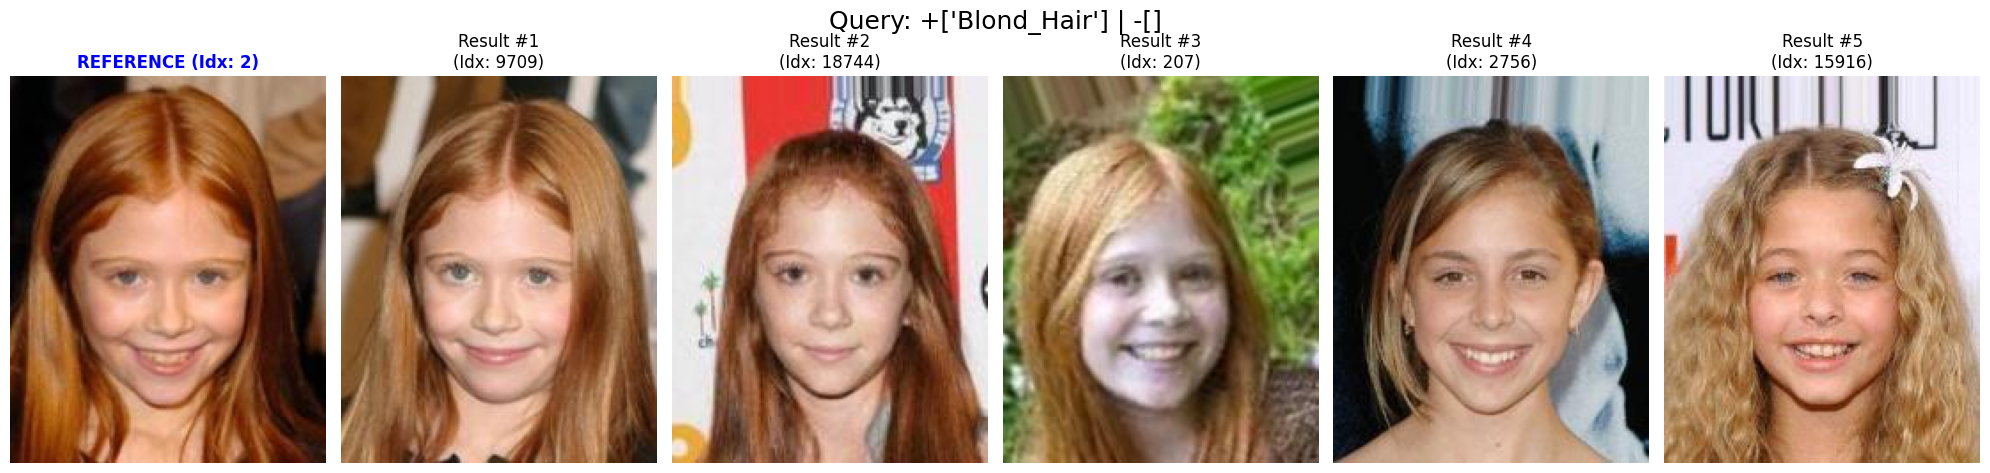

Example result for query:  -Male, -Mustache
Parameters: a=0.2023  b=0.3524  c=0.1606  alpha=0.3 (fixed)


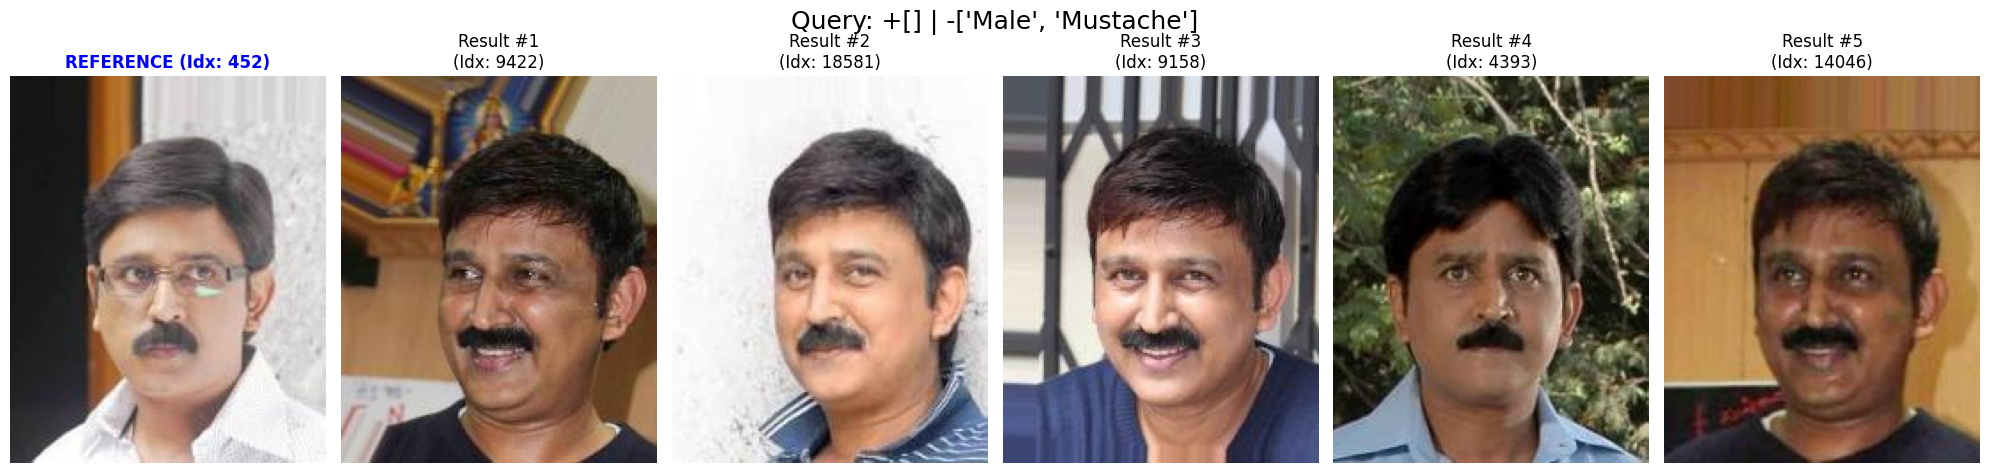

Example result for query:  +Chubby, -Young
Parameters: a=0.2023  b=0.3524  c=0.1606  alpha=0.3 (fixed)


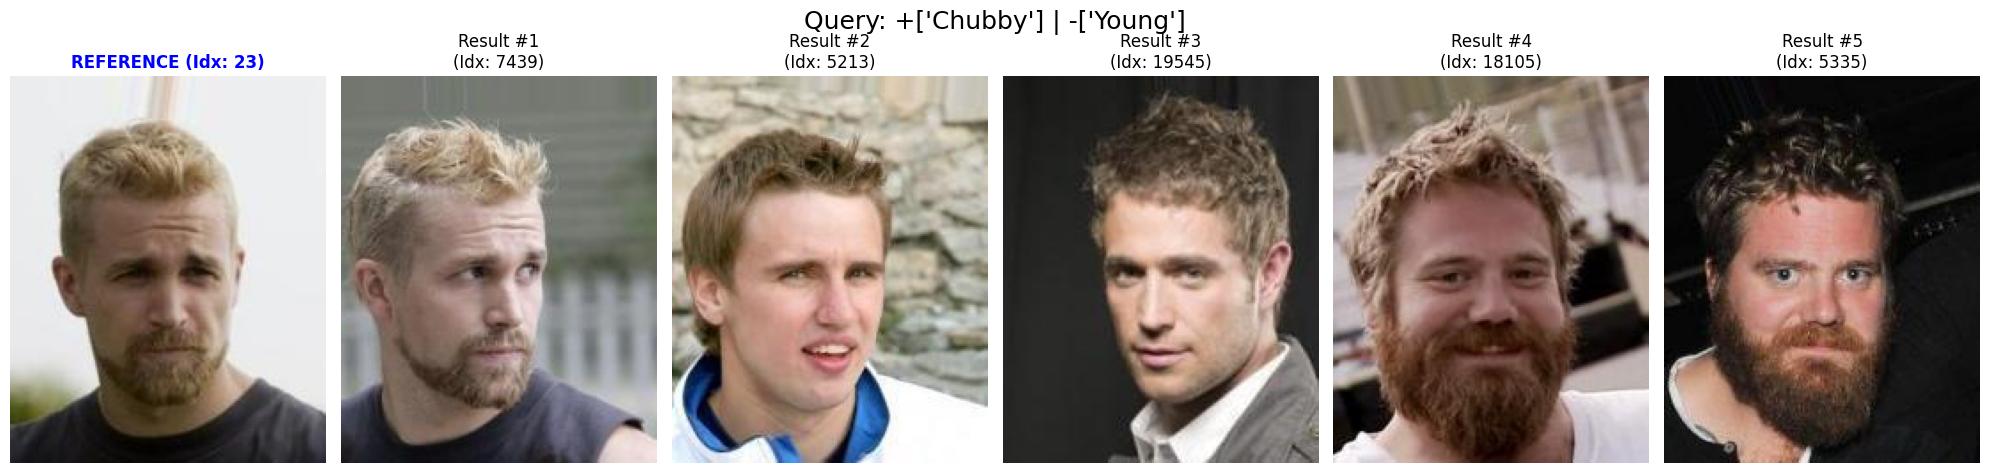

(array([ 7439,  5213, 19545, 18105,  5335]),
 array([0.8498077 , 0.80433995, 0.79102737, 0.78393   , 0.7828667 ],
       dtype=float32))

In [ ]:
#example of output

print("Example result for query: ", annotations[5]["query"])
print(f"Parameters: a={a_ptr:.4f}  b={b_ptr:.4f}  c={c_ptr:.4f}  alpha={ALPHA_FIXED} (fixed)")
parameter_image_retrieval(annotations[5], a_ptr, b_ptr, c_ptr, ALPHA_FIXED, database_embeddings, processor, model, device)

print("Example result for query: ", annotations[10]["query"])
print(f"Parameters: a={a_ptr:.4f}  b={b_ptr:.4f}  c={c_ptr:.4f}  alpha={ALPHA_FIXED} (fixed)")
parameter_image_retrieval(annotations[10], a_ptr, b_ptr, c_ptr, ALPHA_FIXED, database_embeddings, processor, model, device)

print("Example result for query: ", annotations[11]["query"])
print(f"Parameters: a={a_ptr:.4f}  b={b_ptr:.4f}  c={c_ptr:.4f}  alpha={ALPHA_FIXED} (fixed)")
parameter_image_retrieval(annotations[11], a_ptr, b_ptr, c_ptr, ALPHA_FIXED, database_embeddings, processor, model, device)


In [ ]:
K_VALUES        = [1, 5, 10]
comparison_data = []

db_norm = F.normalize(database_embeddings, p=2, dim=-1).to(device)

print(f"\n--- Pointer optimizer comparison table (K = {K_VALUES}) ---")

with torch.no_grad():
    for ann in annotations:
        query_str        = ann["query"]
        ground_truth_map = ann["ground_truth"]

        emb           = annotations_mean[query_str]
        pos_emb_mean  = get_mean_emb(emb['pos_sinonimi_emb_mean'],  model.config, device)
        neg_emb_mean  = get_mean_emb(emb['neg_sinonimi_emb_mean'],  model.config, device)
        cont_emb_mean = get_mean_emb(emb['neg_contrari_emb_mean'],  model.config, device)

        r_vals = {k: [] for k in K_VALUES}
        p_vals = {k: [] for k in K_VALUES}

        for ref_idx_str, gt_indices in ground_truth_map.items():
            ref_idx = int(ref_idx_str)
            if not gt_indices:
                continue

            ref_emb = db_norm[ref_idx].unsqueeze(0)
            pointer = (ALPHA_FIXED * ref_emb
                       + (1 - ALPHA_FIXED) * (a_ptr * pos_emb_mean
                                              - b_ptr * neg_emb_mean
                                              + c_ptr * cont_emb_mean))
            pointer         = F.normalize(pointer, p=2, dim=-1)
            scores          = (pointer @ db_norm.T).squeeze(0)
            scores[ref_idx] = -1e9

            top_k = scores.topk(max(K_VALUES)).indices.tolist()

            for k in K_VALUES:
                metrics = evaluate_retrieval(top_k, gt_indices, k)
                r_vals[k].append(metrics[f"Recall@{k}"])
                p_vals[k].append(metrics[f"Precision@{k}"])

        row = {"Query": query_str}
        for k in K_VALUES:
            r_opt  = float(np.mean(r_vals[k])) if r_vals[k] else 0.0
            p_opt  = float(np.mean(p_vals[k])) if p_vals[k] else 0.0
            r_base = evaluation_results[query_str].get(f"Recall@{k}",    0.0)
            p_base = evaluation_results[query_str].get(f"Precision@{k}", 0.0)
            row[f"R@{k} Base"] = r_base
            row[f"R@{k} Opt"]  = r_opt
            row[f"R@{k} Δ"]    = r_opt - r_base
            row[f"P@{k} Base"] = p_base
            row[f"P@{k} Opt"]  = p_opt
            row[f"P@{k} Δ"]    = p_opt - p_base
        comparison_data.append(row)

comparison_df = pd.DataFrame(comparison_data).set_index("Query")

# Average row
avg_row      = comparison_df.mean(numeric_only=True)
avg_row.name = "Average"
comparison_df = pd.concat([comparison_df, avg_row.to_frame().T])

# Formatting
for col in comparison_df.columns:
    if "Δ" in col:
        comparison_df[col] = comparison_df[col].apply(lambda x: f"{x*100:+.2f}%")
    else:
        comparison_df[col] = comparison_df[col].apply(lambda x: f"{x*100:.2f}%")

display(comparison_df)



--- Pointer optimizer comparison table (K = [1, 5, 10]) ---


,R@1 Base,R@1 Opt,R@1 Δ,P@1 Base,P@1 Opt,P@1 Δ,R@5 Base,R@5 Opt,R@5 Δ,P@5 Base,P@5 Opt,P@5 Δ,R@10 Base,R@10 Opt,R@10 Δ,P@10 Base,P@10 Opt,P@10 Δ
+Smiling,6.52%,5.27%,-1.25%,6.52%,5.27%,-1.25%,18.28%,16.55%,-1.73%,4.80%,4.26%,-0.54%,25.68%,23.63%,-2.05%,3.98%,3.59%,-0.39%
+Eyeglasses,1.78%,1.05%,-0.73%,1.78%,1.05%,-0.73%,7.74%,5.69%,-2.05%,1.81%,1.33%,-0.48%,12.07%,9.61%,-2.46%,1.58%,1.28%,-0.30%
-Heavy_Makeup,2.79%,2.50%,-0.29%,2.79%,2.50%,-0.29%,9.15%,8.88%,-0.27%,2.10%,2.03%,-0.08%,14.44%,14.00%,-0.44%,1.81%,1.77%,-0.04%
+Male,0.56%,0.56%,+0.00%,0.56%,0.56%,+0.00%,1.19%,1.38%,+0.19%,0.33%,0.36%,+0.04%,1.82%,1.88%,+0.06%,0.27%,0.29%,+0.02%
-Young,0.92%,0.99%,+0.07%,0.92%,0.99%,+0.07%,3.10%,2.71%,-0.39%,0.74%,0.68%,-0.06%,5.30%,4.87%,-0.43%,0.70%,0.65%,-0.05%
+Blond_Hair,2.21%,2.03%,-0.18%,2.21%,2.03%,-0.18%,7.99%,6.40%,-1.59%,2.10%,1.70%,-0.40%,12.54%,9.45%,-3.09%,1.88%,1.48%,-0.39%
+Mustache,6.31%,7.31%,+1.00%,6.31%,7.31%,+1.00%,16.94%,14.62%,-2.33%,4.78%,4.19%,-0.60%,23.92%,20.27%,-3.65%,3.75%,3.22%,-0.53%
-Young,0.92%,0.99%,+0.07%,0.92%,0.99%,+0.07%,3.10%,2.71%,-0.39%,0.74%,0.68%,-0.06%,5.30%,4.87%,-0.43%,0.70%,0.65%,-0.05%
"+Eyeglasses, +Smiling",1.80%,0.49%,-1.31%,1.80%,0.49%,-1.31%,5.07%,1.80%,-3.27%,1.21%,0.36%,-0.85%,8.33%,2.94%,-5.39%,0.98%,0.38%,-0.60%
"+Black_Hair, -Wavy_Hair",2.84%,1.56%,-1.28%,2.84%,1.56%,-1.28%,8.98%,5.68%,-3.30%,2.08%,1.31%,-0.78%,14.70%,9.56%,-5.13%,1.92%,1.29%,-0.62%


### Discussion

Results are a little bit worse than the baseline. This is expected for two reasons:

1. **Global weights cannot adapt to query complexity** — the same `(a, b, c)` must serve
   both simple and multi-condition queries, forcing a compromise that is suboptimal for both.
2. **Train/test distribution mismatch** — training pairs are generated from the full 19,962
   images while the evaluation JSON uses a curated subset with ≥ 5 ground-truth targets per
   reference. The optimizer may overfit to easy pairs (with many ground-truth targets) that
   are underrepresented in the evaluation set.

Both limitations are addressed in the final model: the MLP predicts per-query weights,
and the CLAY-derived `µ_c` vectors provide richer, manifold-aware text anchors.



# CLAY — Geometric Conditioning Pipeline

We implement the core building blocks of CLAY (Lim et al., CVPR 2026): a training-free
conditional similarity metric that operates on the unit hypersphere geometry of CLIP embeddings.
The pipeline projects visual features into a text-conditional subspace, enabling retrieval
conditioned on semantic attributes without retraining the backbone.


In [41]:
def normalize(v: torch.Tensor) -> torch.Tensor:
    """L2 normalize a vector or matrix of vectors."""
    return v / v.norm(dim=-1, keepdim=True).clamp(min=1e-8)


def log_map(x: torch.Tensor, mu: torch.Tensor) -> torch.Tensor:
    """
    Logarithm map: projects points x onto the tangent space at mu.
    Both x and mu must be L2-normalized (on the unit hypersphere).
    x:  (N, d) or (d,)
    mu: (d,)
    """
    mu = mu / mu.norm().clamp(min=1e-8)
    if x.dim() == 1:
        x = x.unsqueeze(0)

    dot = (x @ mu).clamp(-1 + 1e-6, 1 - 1e-6).unsqueeze(-1)
    theta = torch.arccos(dot)

    tangent = x - mu.unsqueeze(0) * dot
    # avoid division by zero when x ≈ mu
    scale = torch.where(theta.abs() < 1e-6,
                        torch.ones_like(theta),
                        theta / torch.sin(theta))
    return tangent * scale


We first build the pipeline step by step on a single query to verify each component,
then generalize by precomputing projection matrices for all attributes.

Generating text feature mapping

*" Specifically, following previous
works [9, 29], we first generate condition-related textual
prompts through Large-Language Model (LLM) with the
template: a photo of {c}. The generated text prompts
are then encoded through a text encoder fT and their text
embeddings t are concatenated to form the text feature matrix Tc = [t
c
1
, . . . , t
c
n
]
⊤ ∈ R
n×d
. "*

In [42]:
#check for a positive and negative query
for i, ann in enumerate(annotations):
    print(i, ")", ann["query"])

0 ) +Smiling
1 ) +Eyeglasses
2 ) -Heavy_Makeup
3 ) +Male
4 ) -Young
5 ) +Blond_Hair
6 ) +Mustache
7 ) -Young
8 ) +Eyeglasses, +Smiling
9 ) +Black_Hair, -Wavy_Hair
10 ) -Male, -Mustache
11 ) +Chubby, -Young
12 ) -Smiling, +Eyeglasses, +Wearing_Hat
13 ) +Wearing_Lipstick, -Heavy_Makeup, +Smiling


In [43]:
#we process query 9: +Black_Hair, -Wavy_Hair
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

query_text = annotations[11]["query"]

# Parse the query string
pos_attrs, neg_attrs = parse_query_string(query_text)

# Clean the parsed attributes
pos_attrs_cleaned, neg_attrs_cleaned = clean_query(pos_attrs, neg_attrs)

current_query_pos_embeddings = []
current_query_neg_embeddings = []

for attr in pos_attrs_cleaned:
    expansion = get_expansion(attr)
    best_pos_prompts = best_expansions[attr]["synon"]
    best_neg_prompts = best_expansions[attr]["contr"]
    # Add embeddings of positive expanded terms
    for prompt in best_pos_prompts:
        current_query_pos_embeddings.append(get_text_embedding(prompt, processor, model, device))
    # Add embeddings of negative expanded terms (antonyms)
    for prompt in best_neg_prompts:
        current_query_neg_embeddings.append(get_text_embedding(prompt, processor, model, device))

for attr in neg_attrs_cleaned:
    expansion = get_expansion(attr)
    best_pos_prompts = best_expansions[attr]["synon"]
    best_neg_prompts = best_expansions[attr]["contr"]
    # Add embeddings of positive expanded terms
    for prompt in best_pos_prompts:
        current_query_neg_embeddings.append(get_text_embedding(prompt, processor, model, device))
    # Add embeddings of negative expanded terms (antonyms)
    for prompt in best_neg_prompts:
        current_query_pos_embeddings.append(get_text_embedding(prompt, processor, model, device))

Tc_pos = torch.stack(current_query_pos_embeddings).to(device)
Tc_neg = torch.stack(current_query_neg_embeddings).to(device)



We now create the logarithmic maps

*"Embedding geometry of each modality tends to be concentrated within a conical region, indicating that most embeddings lie closer to a common mean direction. Hence,
we leverage the validity of the local tangent space approximation under this geometric property. Formally, any point
x ∈ Sd−1 \ {−µ} can be mapped onto the tangent space
Tµ = {x ∈ R
d
: x
⊤µ = 0} via logarithm map:
logµ(x) := (x − µ(x
⊤µ)) θ
sin(θ)
,
θ = arccos(x
⊤µ).*"

*"We consider the normalized mean µc of text features Tc as a
reference point for defining the tangent space, and map text
features from the unit hypersphere manifold to the tangent
space of µc with logarithm map.*"

*"logµc
(Tc) =
logµc
(t
c
1
)· · ·logµc
(t
c
n
)
⊤
,
logµc
(Tc) = UΣV⊤"*

In [44]:
mu_c_pos = normalize(Tc_pos.mean(dim=0))
mu_c_neg = normalize(Tc_neg.mean(dim=0))

log_Tc_pos = log_map(Tc_pos, mu_c_pos)
log_Tc_neg = log_map(Tc_neg, mu_c_neg)

*"We apply SVD on these mapped text features. We utilize the top-k right singular vectors to construct textual subspace, defined as span(Vk), and obtain the projection matrix Pc = VkVk
⊤. "*

In [45]:
U_pos, S_pos, Vt_pos = torch.linalg.svd(log_Tc_pos, full_matrices=False)
U_neg, S_neg, Vt_neg = torch.linalg.svd(log_Tc_neg, full_matrices=False)

#using 3 as top-k
k = 3
Vk_pos = Vt_pos[:k].T
Vk_neg = Vt_neg[:k].T

Pc_pos = Vk_pos @ Vk_pos.T
Pc_neg = Vk_neg @ Vk_neg.T


We can generalize and precompute positive and negative projection matrices for each attribute, in order to simply substitute in the next steps. We will store them in a dictionary for simplicity.

*"By precomputing these textual
subspaces for each condition (i.e., projection matrices), we
only need to modulate the conditional similarity space using
precomputed projection matrices at inference, accordingly.
Specifically, we project the query and database visual features from pre-trained VLMs into the space that satisfies the
desired conditional relationships, without re-encoding."*

In [46]:
def build_feature_matrix(attr, device):
  '''
  Builds two embedding matrices for a given attribute using its best synonyms (positive prompts) and contraries (negative prompts).
  Returns stacked, device-ready tensors for both sets, handling empty cases safely.
  '''
  cleaned_attr = clean_attr(attr)
  expansion_for_attr = best_expansions.get(cleaned_attr, {"synon": [], "contr": []})

  best_pos_prompts = expansion_for_attr["synon"]
  best_neg_prompts = expansion_for_attr["contr"]

  pos_attr_embeddings = []
  neg_attr_add_embeddings = []

  # Add embeddings for positive prompts
  for prompt in best_pos_prompts:
    pos_attr_embeddings.append(get_text_embedding(f"A picture of a person with {prompt}", processor, model, device))

  # Add embeddings for negative prompts (contraries)
  for prompt in best_neg_prompts:
    neg_attr_add_embeddings.append(get_text_embedding(f"A picture of a person with {prompt}", processor, model, device))

  if not pos_attr_embeddings:
    # Return an empty tensor of the correct shape (embedding dimension is 512)
    pos_embeddings_tensor = torch.empty(0, 512, device=device)
  else:
    pos_embeddings_tensor = torch.stack(pos_attr_embeddings).to(device)

  if not neg_attr_add_embeddings:
    neg_add_embeddings_tensor = torch.empty(0, 512, device=device)
  else:
    neg_add_embeddings_tensor = torch.stack(neg_attr_add_embeddings).to(device)

  return pos_embeddings_tensor, neg_add_embeddings_tensor

In [47]:
def build_log_map(embeddings, device):
  '''
  Computes the centroid (`mu`) and maps to the tangent space using a logarithmic map.
  '''
  if embeddings.numel() == 0:
    # Return zero tensors for mu and log_Tc if embeddings are empty
    return torch.zeros(512, device=device), torch.empty(0, 512, device=device)

  embeddings = embeddings.to(device)
  mu = normalize(embeddings.mean(dim=0)).to(device)
  log_Tc = log_map(embeddings, mu)

  return mu, log_Tc

In [48]:
def build_projection_matrix(attr, k=3):
  '''
  Builds projection matrices for an attribute by applying SVD on the tangent-space embeddings of its synonyms and contraries.
  Returns low-rank subspace projectors (Pc) along with their centroids for positive and negative directions.
  '''
  device = "cuda" if torch.cuda.is_available() else "cpu"
  model.to(device)
  pos_attr_embeddings, neg_attr_add_embeddings = build_feature_matrix(attr, device)

  mu_pos, log_pos_attr = build_log_map(pos_attr_embeddings, device)
  mu_neg, log_neg_attr_add = build_log_map(neg_attr_add_embeddings, device)

  # Handle empty log_Tc tensors for SVD
  if log_pos_attr.numel() == 0:
    Pc_pos = torch.zeros(512, 512, device=device)
  else:
    U_pos, S_pos, Vt_pos = torch.linalg.svd(log_pos_attr, full_matrices=False)
    # Ensure k does not exceed the number of singular vectors available
    actual_k_pos = min(k, Vt_pos.shape[0])
    if actual_k_pos == 0:
        Pc_pos = torch.zeros(512, 512, device=device)
    else:
        Vk_pos = Vt_pos[:actual_k_pos].T
        Pc_pos = Vk_pos @ Vk_pos.T

  if log_neg_attr_add.numel() == 0:
    Pc_neg_add = torch.zeros(512, 512, device=device)
  else:
    U_neg_add, S_neg_add, Vt_neg_add = torch.linalg.svd(log_neg_attr_add, full_matrices=False)
    # Ensure k does not exceed the number of singular vectors available
    actual_k_neg = min(k, Vt_neg_add.shape[0])
    if actual_k_neg == 0:
        Pc_neg_add = torch.zeros(512, 512, device=device)
    else:
        Vk_neg_add = Vt_neg_add[:actual_k_neg].T
        Pc_neg_add = Vk_neg_add @ Vk_neg_add.T

  return (Pc_pos, mu_pos), (Pc_neg_add, mu_neg)

In [49]:
#building the dictionary
projection_matrices = {}

for key in BASE_POOL:
  Pc_pos, Pc_neg_add = build_projection_matrix(key)
  projection_matrices[key] = {
      "pos": Pc_pos,
      "neg_add": Pc_neg_add,
      "neg_sub": Pc_pos
  }
  #"pos": (pc, mu)
  #"neg_add": (pc, mu)
  #"neg sub": (pc, mu)




In [ ]:
print(projection_matrices.keys())

dict_keys(['5 o clock shadow', 'arched eyebrows', 'attractive', 'bags under eyes', 'bald', 'bangs', 'big lips', 'big nose', 'black hair', 'blond hair', 'blurry', 'brown hair', 'bushy eyebrows', 'chubby', 'double chin', 'eyeglasses', 'goatee', 'gray hair', 'heavy makeup', 'high cheekbones', 'male', 'mouth slightly open', 'mustache', 'narrow eyes', 'no beard', 'oval face', 'pale skin', 'pointy nose', 'receding hairline', 'rosy cheeks', 'sideburns', 'smiling', 'straight hair', 'wavy hair', 'wearing earrings', 'wearing hat', 'wearing lipstick', 'wearing necklace', 'wearing necktie', 'young'])


### Building modularity function

*"To mitigate conic effects, we apply rotation H(·) to align the mean
of the database visual features µvd with the mean of text
features µc
, without altering the intra-relationship among
the visual features. We then apply the logarithm map to
map the rotated visual features H(v) onto the tangent space
at µc
, and subsequently project them onto the textual subspace with projection matrix Pc."*

mCLAY(v, c) := Pc logµc
(H(v)),

In [50]:
def rotation_matrix(mu_c, mu_vd, device):

  mu_c = (mu_c / mu_c.norm()).to(device)
  mu_vd = (mu_vd / mu_vd.norm()).to(device)
  M = mu_c.unsqueeze(1) @ mu_vd.unsqueeze(0)
  U, _, Vt = torch.linalg.svd(M)
  R = U @ Vt

  return R

In [51]:
def H(R, v):
  return R @ v

In [52]:
#already computing mu for next steps
mu_vd = database_embeddings.mean(dim=0)

In [53]:
#we do a check for a simple attribute from the dictionary
#because we are centering the dataset mean on the attribute one the dot product should be 1 more or less

mu_c = projection_matrices["bald"]["pos"][1]
R = rotation_matrix(mu_c, mu_vd, device)
mu_vd = mu_vd / mu_vd.norm()
mv_centered = H(R.to(device), mu_vd.to(device))

print("Before: mv = ",mu_vd.norm(), "mu_c = ", mu_c.norm(), "dot product", (mv_centered.dot(mu_c)))
print("After: mv = ",mv_centered.norm(), "dot product", (mv_centered.dot(mu_c)))


Before: mv =  tensor(1.) mu_c =  tensor(1.0000, device='cuda:0') dot product tensor(1.0000, device='cuda:0')
After: mv =  tensor(1.0000, device='cuda:0') dot product tensor(1.0000, device='cuda:0')


Building a function that correctly computes mean embeddings for the query

In [54]:
all_query_Tc = {}

for i, ann in tqdm(enumerate(annotations), total=len(annotations)):

    query_text = ann['query']
    Tc_list = []

    pos_attrs, neg_attrs = parse_query_string(query_text)
    pos_attrs_cleaned, neg_attrs_cleaned = clean_query(pos_attrs, neg_attrs)

    for attr in pos_attrs_cleaned:
        pos_attr_embeddings, _ = build_feature_matrix(attr, device)
        Tc_list.append(pos_attr_embeddings)

    for attr in neg_attrs_cleaned:
        neg_sub, neg_add = build_feature_matrix(attr, device)
        Tc_list.append(neg_sub)
        Tc_list.append(neg_add)

    Tc = torch.cat(Tc_list, dim=0)

    mu_c = Tc.mean(dim=0)
    mu_c = mu_c / mu_c.norm()

    all_query_Tc[query_text] = {
        "Tc": Tc,
        "mu_c": mu_c
    }

  0%|          | 0/14 [00:00<?, ?it/s]

Computing projection matrices as weighted sums of each singular Pc

In [55]:
def weighted_pc(Pc_list, weights):
    Pc_stack = torch.stack(Pc_list)
    weights = torch.softmax(weights, dim=0)
    return (weights.view(-1,1,1) * Pc_stack).sum(dim=0)

Building a basic clay similarity function on which we will then work with training

*"csimCLAY(Iq, Id | c) := d(m(Iq, c), m(Id, c))"*


In [56]:
def clay_similarity(ref_vec, database_embeddings, Pc, mu_query, R):

    vq_rot = R @ ref_vec
    vd_rot = (R @ database_embeddings.T).T

    vq_log = log_map(vq_rot.unsqueeze(0), mu_query).squeeze(0)
    vd_log = log_map(vd_rot, mu_query)

    vq_proj = Pc @ vq_log
    vd_proj = (Pc @ vd_log.T).T

    vq_proj = vq_proj / vq_proj.norm()
    vd_proj = vd_proj / vd_proj.norm(dim=1, keepdim=True)

    return vq_proj @ vd_proj.T

# Optimizer using CLAY pipeline


`train_clay` iterates over all training pairs, builds the composite `Pc` per query on the
fly, computes blended scores, and updates `(a, b, c)` via the ranking loss. `α = ALPHA_FIXED`
ensures the identity signal is always preserved during training, consistent with evaluation.


In [ ]:
def train_clay(
    train_pairs,
    projection_matrices,
    database_embeddings,
    all_query_Tc,
    epochs = 20,
    lr     = 1e-2,
    device = "cuda",
):
    """
    Learns global (a, b, c) for Pc = a*Pc_pos + b*Pc_neg_add - c*Pc_neg_sub.
    Alpha is fixed at ALPHA_FIXED for consistency across the project.
    Accepts train_pairs (attribute-based, NOT eval JSON).
    """

    a         = torch.nn.Parameter(torch.tensor(1.0, device=device))
    b         = torch.nn.Parameter(torch.tensor(0.5, device=device))
    c         = torch.nn.Parameter(torch.tensor(0.3, device=device))
    optimizer = torch.optim.Adam([a, b, c], lr=lr)

    db_norm = F.normalize(database_embeddings, p=2, dim=-1).to(device)
    mu_vd   = F.normalize(database_embeddings.mean(dim=0), p=2, dim=-1).to(device)
    zero_dd = torch.zeros(512, 512, device=device)

    for epoch in range(epochs):
        total_loss, n_steps = 0.0, 0
        shuffled = train_pairs.copy()
        random.shuffle(shuffled)

        for pair in tqdm(shuffled, desc=f"Epoch {epoch+1}/{epochs}", leave=False):
            ref_idx    = pair["ref_idx"]
            pos_attrs  = pair["pos_attrs"]
            neg_attrs  = pair["neg_attrs"]
            query      = pair["query"]
            gt_indices = [i for i in pair["gt_indices"] if i < len(db_norm)]
            if not gt_indices:
                continue

            Pc_pos_list, Pc_neg_add_list, Pc_neg_sub_list = [], [], []

            for attr in pos_attrs:
                if attr not in projection_matrices:
                    continue
                Pc_pos_list.append(projection_matrices[attr]["pos"][0].to(device))

            for attr in neg_attrs:
                if attr not in projection_matrices:
                    continue
                Pc_neg_add_list.append(projection_matrices[attr]["neg_add"][0].to(device))
                Pc_neg_sub_list.append(projection_matrices[attr]["neg_sub"][0].to(device))

            if not Pc_pos_list and not Pc_neg_add_list:
                continue

            Pc_pos     = torch.stack(Pc_pos_list).mean(0)     if Pc_pos_list     else zero_dd
            Pc_neg_add = torch.stack(Pc_neg_add_list).mean(0) if Pc_neg_add_list else zero_dd
            Pc_neg_sub = torch.stack(Pc_neg_sub_list).mean(0) if Pc_neg_sub_list else zero_dd

            Pc = a * Pc_pos + b * Pc_neg_add - c * Pc_neg_sub

            mu_c = all_query_Tc[query]["mu_c"].to(device)
            R    = rotation_matrix(mu_c, mu_vd, device)

            ref_vec     = db_norm[ref_idx]
            scores_clay = clay_similarity(ref_vec, db_norm, Pc, mu_c, R)
            scores_id   = db_norm @ ref_vec
            scores      = ALPHA_FIXED * scores_id + (1 - ALPHA_FIXED) * scores_clay

            loss = loss_fn2(scores, gt_indices)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            n_steps    += 1

        avg = total_loss / n_steps if n_steps else float("nan")
        print(f"Epoch {epoch+1}/{epochs}  avg_loss={avg:.4f}  "
              f"a={a.item():.4f}  b={b.item():.4f}  c={c.item():.4f}  "
              f"alpha={ALPHA_FIXED} (fixed)")
        print(f"Gradients → a={a.grad.item():.4f}  b={b.grad.item():.4f}  "
              f"c={c.grad.item():.4f}")

    return a, b, c


In [ ]:
def evaluate_clay_params(
    annotations,
    database_embeddings,
    projection_matrices,
    all_query_Tc,
    evaluation_results,
    a_fixed,
    b_fixed,
    c_fixed,
    alpha_fixed,
    k_eval  = 10,
    device  = "cuda",
):
    """
    Evaluates learned CLAY parameters on the full benchmark.
    Reports Recall@1/5/10 and Precision@1/5/10 per query with delta vs baseline.
    """

    EVAL_K_VALUES = [1, 5, k_eval]

    db_norm = F.normalize(database_embeddings, p=2, dim=-1).to(device)
    mu_vd   = F.normalize(database_embeddings.mean(dim=0), p=2, dim=-1).to(device)
    zero_dd = torch.zeros(512, 512, device=device)
    rows    = []

    with torch.no_grad():
        for ann in tqdm(annotations, desc="Evaluating CLAY"):
            query   = ann["query"]
            gt_dict = ann["ground_truth"]

            pos_attrs, neg_attrs = parse_query_string(query)
            pos_attrs, neg_attrs = clean_query(pos_attrs, neg_attrs)

            # ── build Pc for this query — computed once, reused per ref ─
            Pc_pos_list, Pc_neg_add_list, Pc_neg_sub_list = [], [], []

            for attr in pos_attrs:
                if attr not in projection_matrices:
                    continue
                Pc_pos_list.append(projection_matrices[attr]["pos"][0].to(device))

            for attr in neg_attrs:
                if attr not in projection_matrices:
                    continue
                Pc_neg_add_list.append(projection_matrices[attr]["neg_add"][0].to(device))
                Pc_neg_sub_list.append(projection_matrices[attr]["neg_sub"][0].to(device))

            Pc_pos     = torch.stack(Pc_pos_list).mean(0)     if Pc_pos_list     else zero_dd
            Pc_neg_add = torch.stack(Pc_neg_add_list).mean(0) if Pc_neg_add_list else zero_dd
            Pc_neg_sub = torch.stack(Pc_neg_sub_list).mean(0) if Pc_neg_sub_list else zero_dd

            Pc   = a_fixed * Pc_pos + b_fixed * Pc_neg_add - c_fixed * Pc_neg_sub
            mu_c = all_query_Tc[query]["mu_c"].to(device)
            R    = rotation_matrix(mu_c, mu_vd, device)   # maps mu_vd → mu_c

            q_recalls    = {k: [] for k in EVAL_K_VALUES}
            q_precisions = {k: [] for k in EVAL_K_VALUES}

            for ref_idx_str, gt_indices in gt_dict.items():
                ref_idx = int(ref_idx_str)
                if not gt_indices:
                    continue

                ref_vec     = db_norm[ref_idx]
                scores_clay = clay_similarity(ref_vec, db_norm, Pc, mu_c, R)
                scores_id   = db_norm @ ref_vec
                scores      = alpha_fixed * scores_id + (1 - alpha_fixed) * scores_clay
                scores[ref_idx] = -1e9

                _, top_k  = torch.topk(scores, k=max(EVAL_K_VALUES))
                retrieved = top_k.cpu().tolist()

                for k in EVAL_K_VALUES:
                    res = evaluate_retrieval(retrieved, gt_indices, k=k)
                    q_recalls[k].append(res[f"Recall@{k}"])
                    q_precisions[k].append(res[f"Precision@{k}"])

            # ── per-query row with baseline comparison ───────────────
            baseline = evaluation_results.get(query, {})
            row = {"Query": query}
            for k in EVAL_K_VALUES:
                r      = float(np.mean(q_recalls[k]))    if q_recalls[k]    else 0.0
                p      = float(np.mean(q_precisions[k])) if q_precisions[k] else 0.0
                r_base = baseline.get(f"Recall@{k}",    0.0)
                p_base = baseline.get(f"Precision@{k}", 0.0)
                row[f"R@{k} (base)"] = f"{r_base*100:.2f}%"
                row[f"R@{k} (clay)"] = f"{r*100:.2f}%"
                row[f"R@{k} Δ"]      = f"{(r - r_base)*100:+.2f}%"
                row[f"P@{k} (base)"] = f"{p_base*100:.2f}%"
                row[f"P@{k} (clay)"] = f"{p*100:.2f}%"
                row[f"P@{k} Δ"]      = f"{(p - p_base)*100:+.2f}%"
            rows.append(row)

    df = pd.DataFrame(rows).set_index("Query")
    display(df)
    return df


### Training


In [ ]:
a1, b1, c1 = train_clay(
    train_pairs, projection_matrices, database_embeddings, all_query_Tc,
    epochs=10, lr=1e-2, device=device,
)


Epoch 1/10:   0%|          | 0/1517 [00:00<?, ?it/s]

Epoch 1/10  avg_loss=0.3378  a=0.6155  b=0.6511  c=0.6115  alpha=0.3 (fixed)
Gradients → a=0.0515  b=0.0352  c=-0.0895


Epoch 2/10:   0%|          | 0/1517 [00:00<?, ?it/s]

Epoch 2/10  avg_loss=0.3371  a=0.7790  b=0.6650  c=0.7362  alpha=0.3 (fixed)
Gradients → a=0.1013  b=-0.0706  c=-0.0440


Epoch 3/10:   0%|          | 0/1517 [00:00<?, ?it/s]

...

Epoch 8/10  avg_loss=0.3367  a=1.2083  b=1.1396  c=1.1058  alpha=0.3 (fixed)
Gradients → a=-0.0000  b=0.0000  c=0.0000


Epoch 9/10:   0%|          | 0/1517 [00:00<?, ?it/s]

Epoch 9/10  avg_loss=0.3365  a=1.0955  b=1.1745  c=1.2620  alpha=0.3 (fixed)
Gradients → a=0.0000  b=0.0707  c=-0.0662


Epoch 10/10:   0%|          | 0/1517 [00:00<?, ?it/s]

Epoch 10/10  avg_loss=0.3368  a=1.3420  b=1.2118  c=1.2369  alpha=0.3 (fixed)
Gradients → a=0.0000  b=-0.0068  c=0.0067


### Evaluation
`evaluate_clay_params` replicates the same Pc construction at test time using the learned
fixed weights, then reports R@1/5/10 and P@1/5/10 per query with delta vs. baseline.


In [ ]:
clay_results = evaluate_clay_params(
    annotations, database_embeddings, projection_matrices, all_query_Tc,
    evaluation_results,
    a_fixed=a1.item(), b_fixed=b1.item(), c_fixed=c1.item(),
    alpha_fixed = ALPHA_FIXED,
    k_eval=10, device=device,
)


Evaluating CLAY:   0%|          | 0/14 [00:00<?, ?it/s]

,R@1 (base),R@1 (clay),R@1 Δ,P@1 (base),P@1 (clay),P@1 Δ,R@5 (base),R@5 (clay),R@5 Δ,P@5 (base),P@5 (clay),P@5 Δ,R@10 (base),R@10 (clay),R@10 Δ,P@10 (base),P@10 (clay),P@10 Δ
Query,,,,,,,,,,,,,,,,,,
+Smiling,6.52%,2.76%,-3.76%,6.52%,2.76%,-3.76%,18.28%,8.27%,-10.01%,4.80%,1.90%,-2.90%,25.68%,11.64%,-14.04%,3.98%,1.49%,-2.50%
+Eyeglasses,1.78%,0.73%,-1.05%,1.78%,0.73%,-1.05%,7.74%,2.82%,-4.92%,1.81%,0.63%,-1.18%,12.07%,4.74%,-7.33%,1.58%,0.54%,-1.04%
-Heavy_Makeup,2.79%,1.39%,-1.39%,2.79%,1.39%,-1.39%,9.15%,4.62%,-4.53%,2.10%,0.99%,-1.12%,14.44%,7.24%,-7.19%,1.81%,0.79%,-1.02%
+Male,0.56%,0.38%,-0.19%,0.56%,0.38%,-0.19%,1.19%,1.50%,+0.31%,0.33%,0.35%,+0.03%,1.82%,3.26%,+1.44%,0.27%,0.38%,+0.11%
-Young,0.92%,0.60%,-0.32%,0.92%,0.60%,-0.32%,3.10%,1.96%,-1.14%,0.74%,0.45%,-0.29%,5.30%,3.45%,-1.85%,0.70%,0.41%,-0.29%
+Blond_Hair,2.21%,1.24%,-0.97%,2.21%,1.24%,-0.97%,7.99%,3.69%,-4.30%,2.10%,0.87%,-1.23%,12.54%,6.11%,-6.44%,1.88%,0.74%,-1.14%
+Mustache,6.31%,2.99%,-3.32%,6.31%,2.99%,-3.32%,16.94%,10.63%,-6.31%,4.78%,2.52%,-2.26%,23.92%,12.29%,-11.63%,3.75%,1.56%,-2.19%
-Young,0.92%,0.60%,-0.32%,0.92%,0.60%,-0.32%,3.10%,1.96%,-1.14%,0.74%,0.45%,-0.29%,5.30%,3.45%,-1.85%,0.70%,0.41%,-0.29%
"+Eyeglasses, +Smiling",1.80%,0.00%,-1.80%,1.80%,0.00%,-1.80%,5.07%,0.65%,-4.41%,1.21%,0.13%,-1.08%,8.33%,1.47%,-6.86%,0.98%,0.15%,-0.83%


,R@1 (base),R@1 (clay),R@1 Δ,P@1 (base),P@1 (clay),P@1 Δ,R@5 (base),R@5 (clay),R@5 Δ,P@5 (base),P@5 (clay),P@5 Δ,R@10 (base),R@10 (clay),R@10 Δ,P@10 (base),P@10 (clay),P@10 Δ
Query,,,,,,,,,,,,,,,,,,
+Smiling,6.52%,2.76%,-3.76%,6.52%,2.76%,-3.76%,18.28%,8.27%,-10.01%,4.80%,1.90%,-2.90%,25.68%,11.64%,-14.04%,3.98%,1.49%,-2.50%
+Eyeglasses,1.78%,0.73%,-1.05%,1.78%,0.73%,-1.05%,7.74%,2.82%,-4.92%,1.81%,0.63%,-1.18%,12.07%,4.74%,-7.33%,1.58%,0.54%,-1.04%
-Heavy_Makeup,2.79%,1.39%,-1.39%,2.79%,1.39%,-1.39%,9.15%,4.62%,-4.53%,2.10%,0.99%,-1.12%,14.44%,7.24%,-7.19%,1.81%,0.79%,-1.02%
+Male,0.56%,0.38%,-0.19%,0.56%,0.38%,-0.19%,1.19%,1.50%,+0.31%,0.33%,0.35%,+0.03%,1.82%,3.26%,+1.44%,0.27%,0.38%,+0.11%
-Young,0.92%,0.60%,-0.32%,0.92%,0.60%,-0.32%,3.10%,1.96%,-1.14%,0.74%,0.45%,-0.29%,5.30%,3.45%,-1.85%,0.70%,0.41%,-0.29%
+Blond_Hair,2.21%,1.24%,-0.97%,2.21%,1.24%,-0.97%,7.99%,3.69%,-4.30%,2.10%,0.87%,-1.23%,12.54%,6.11%,-6.44%,1.88%,0.74%,-1.14%
+Mustache,6.31%,2.99%,-3.32%,6.31%,2.99%,-3.32%,16.94%,10.63%,-6.31%,4.78%,2.52%,-2.26%,23.92%,12.29%,-11.63%,3.75%,1.56%,-2.19%
-Young,0.92%,0.60%,-0.32%,0.92%,0.60%,-0.32%,3.10%,1.96%,-1.14%,0.74%,0.45%,-0.29%,5.30%,3.45%,-1.85%,0.70%,0.41%,-0.29%
"+Eyeglasses, +Smiling",1.80%,0.00%,-1.80%,1.80%,0.00%,-1.80%,5.07%,0.65%,-4.41%,1.21%,0.13%,-1.08%,8.33%,1.47%,-6.86%,0.98%,0.15%,-0.83%


### Results Discussion

The CLAY pipeline produces results below the zero-shot baseline on virtually all queries
and all K values. The degradation is consistent across both simple and composed queries,
which rules out query-specific issues and points to a structural problem.

The root cause is the Pc projection: by retaining only k=3 singular vectors per attribute,
we collapse 512 dimensions to a ≤9-dimensional subspace. Every image — regardless of
identity — is mapped to nearly the same low-dimensional region, making cosine similarity
in the projected space essentially random. The `α · cosine(v_ref, db)` blending term
partially mitigates this, but not enough to recover the identity signal lost by the projection.

This is not a failure of the CLAY framework in general — on action or species retrieval
tasks, discarding identity is the correct behavior. On CelebA, where the ground truth
explicitly requires preserving the reference person across 38 non-queried attributes,
the projection works against the objective.

### Towards the Final Model

The CLAY pipeline is not entirely without value. Its manifold-aware construction of `µ_c`
— computed via log-map and SVD over synonym/contrary embeddings — produces richer, more
geometrically grounded text anchors than simple mean embeddings. What fails is the
downstream Pc projection.

The final model keeps what works and replaces what does not:

- **Keep**: CLAY's `µ_c` vectors from `projection_matrices` as text anchors
- **Replace**: Pc projection → full-space pointer arithmetic (identity preserved in 512 dims)
- **Add**: a lightweight MLP that predicts `(a, b, c)` dynamically per query and reference,
  addressing the limitation of fixed global weights from the previous sections


# MLP Hybrid CLAY-Informed MLP

The optimizer above learns fixed global `(a, b, c)`. The MLP replaces them with
**query- and image-adaptive** weights: given the reference image and the three
text-subspace anchors, the MLP predicts `(a, b, c)` dynamically for each retrieval.

**Input** (2048-dim):
```
[ mu_c_pos (512) | mu_c_neg_add (512) | mu_c_neg_sub (512) | ref_emb (512) ]
```
- `mu_c_pos` — normalised mean of positive-attribute synonym text embeddings
- `mu_c_neg_add` — normalised mean of negative-attribute contrary embeddings (push toward opposite)
- `mu_c_neg_sub` — normalised mean of negative-attribute synonym embeddings (suppress this subspace)
- `ref_emb` — normalised CLIP embedding of the reference image

Adding `ref_emb` lets the MLP adapt weights based on what the reference image already
looks like — e.g. predict a higher `a` when the positive condition is far from the ref.

**Output**: `softplus(raw)` → `(a, b, c)` always positive.

In [58]:
# DynamicWeightMLP — predicts per-query (a,b,c) from the 3 semantic mu_c
# vectors and the reference image embedding (4 × 512 = 2048-dim input).
import torch.nn as nn

class DynamicWeightMLP(nn.Module):
    def __init__(self, clip_dim=512, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4 * clip_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 3),
        )

    def forward(self, mu_c_pos, mu_c_neg_add, mu_c_neg_sub, ref_emb):

        x = torch.cat([mu_c_pos, mu_c_neg_add, mu_c_neg_sub, ref_emb], dim=-1)
        raw = self.net(x)
        a = F.softplus(raw[..., 0])
        b = F.softplus(raw[..., 1])
        c = F.softplus(raw[..., 2])
        return a, b, c

In [59]:
# Train DynamicWeightMLP on attribute-based training pairs.
def train_clay_mlp(train_pairs, projection_matrices, database_embeddings,
                   epochs=20, lr=1e-3, clip_dim=512, hidden_dim=256, device=device):
    '''Trains a small MLP that predicts dynamic weights *(a, b, c)* from attribute embeddings and
    a reference image embedding, enabling adaptive query-based transformations instead of fixed coefficients.
    It optimizes these weights via a contrastive-style retrieval loss so that the composed “pointer” embedding
    ranks ground-truth images higher than negatives in the embedding space.
    '''

    db_embs_norm = F.normalize(database_embeddings, p=2, dim=-1).to(device)
    mlp = DynamicWeightMLP(clip_dim=clip_dim, hidden_dim=hidden_dim).to(device)
    opt = torch.optim.Adam(mlp.parameters(), lr=lr)
    temperature = 0.2

    for epoch in range(epochs):
        mlp.train()
        shuffled = train_pairs.copy()
        random.shuffle(shuffled)
        epoch_loss, n = 0.0, 0

        for pair in shuffled:
            ref_idx    = pair["ref_idx"]
            pos_attrs  = pair["pos_attrs"]
            neg_attrs  = pair["neg_attrs"]
            gt_indices = [i for i in pair["gt_indices"] if i < len(db_embs_norm)]
            if not gt_indices:
                continue

            ref_emb = db_embs_norm[ref_idx].unsqueeze(0)

            mu_c_pos     = torch.zeros(1, clip_dim, device=device)
            mu_c_neg_add = torch.zeros(1, clip_dim, device=device)
            mu_c_neg_sub = torch.zeros(1, clip_dim, device=device)

            for attr in pos_attrs:
                if attr in projection_matrices:
                    mu_c_pos += projection_matrices[attr]["pos"][1].unsqueeze(0)
            for attr in neg_attrs:
                if attr in projection_matrices:
                    mu_c_neg_add += projection_matrices[attr]["neg_add"][1].unsqueeze(0)
                    mu_c_neg_sub += projection_matrices[attr]["neg_sub"][1].unsqueeze(0)

            mu_c_pos     = F.normalize(mu_c_pos,     p=2, dim=-1)
            mu_c_neg_add = F.normalize(mu_c_neg_add, p=2, dim=-1)
            mu_c_neg_sub = F.normalize(mu_c_neg_sub, p=2, dim=-1)

            a, b, c = mlp(mu_c_pos, mu_c_neg_add, mu_c_neg_sub, ref_emb)

            # here alpha is 0.5
            pointer = 0.5 * ref_emb + 0.5 * (a * mu_c_pos - b * mu_c_neg_add + c * mu_c_neg_sub)
            pointer = F.normalize(pointer, p=2, dim=-1)

            scores = (pointer @ db_embs_norm.T).squeeze(0) / temperature
            loss   = loss_fn2(scores, gt_indices, margin=0.2)

            opt.zero_grad()
            loss.backward()
            opt.step()

            epoch_loss += loss.item()
            n += 1

        if n > 0:
            print(f"Epoch [{epoch+1}/{epochs}]  loss={epoch_loss/n:.4f}")

    return mlp

In [60]:
# Run MLP training on attribute-based training pairs.
mlp_model = train_clay_mlp(
    train_pairs, projection_matrices, database_embeddings,
    epochs=30, lr=1e-3, clip_dim=512, hidden_dim=256, device=device,
)

Epoch [1/30]  loss=0.1677
Epoch [2/30]  loss=0.1600
Epoch [3/30]  loss=0.1577
Epoch [4/30]  loss=0.1529
Epoch [5/30]  loss=0.1502
Epoch [6/30]  loss=0.1482
Epoch [7/30]  loss=0.1466
Epoch [8/30]  loss=0.1459
Epoch [9/30]  loss=0.1443
Epoch [10/30]  loss=0.1437
Epoch [11/30]  loss=0.1431
Epoch [12/30]  loss=0.1417
Epoch [13/30]  loss=0.1409
Epoch [14/30]  loss=0.1399
Epoch [15/30]  loss=0.1394
Epoch [16/30]  loss=0.1381
Epoch [17/30]  loss=0.1377
Epoch [18/30]  loss=0.1372
Epoch [19/30]  loss=0.1363
Epoch [20/30]  loss=0.1358
Epoch [21/30]  loss=0.1350
Epoch [22/30]  loss=0.1349
Epoch [23/30]  loss=0.1345
Epoch [24/30]  loss=0.1350
Epoch [25/30]  loss=0.1336
Epoch [26/30]  loss=0.1335
Epoch [27/30]  loss=0.1323
Epoch [28/30]  loss=0.1335
Epoch [29/30]  loss=0.1323
Epoch [30/30]  loss=0.1325


### Quantitative Evaluation

We evaluate on all 14 benchmark queries using the official evaluation JSON.


In [61]:
def evaluate_clay_mlp(mlp, annotations, projection_matrices, database_embeddings,
                      evaluation_results, device=device, clip_dim=512):
    '''
    Evaluates the MLP at K=1, K=5, K=10 in a single pass.
    Produces one comparison table per K value (vs zero-shot baseline).
    '''
    mlp.eval()
    db_embs_norm = F.normalize(database_embeddings, p=2, dim=-1).to(device)
    K_VALUES     = [1, 5, 10]

    # per-query results: {query_str: {k: {"r": [...], "p": [...]}}}
    query_results = {}

    with torch.no_grad():
        for ann in annotations:
            query_str        = ann["query"]
            ground_truth_map = ann["ground_truth"]

            pos_attrs_raw, neg_attrs_raw = parse_query_string(query_str)
            pos_attrs, neg_attrs = clean_query(list(pos_attrs_raw), list(neg_attrs_raw))

            mu_c_pos     = torch.zeros(1, clip_dim, device=device)
            mu_c_neg_add = torch.zeros(1, clip_dim, device=device)
            mu_c_neg_sub = torch.zeros(1, clip_dim, device=device)

            for attr in pos_attrs:
                if attr in projection_matrices:
                    mu_c_pos += projection_matrices[attr]["pos"][1].unsqueeze(0)
            for attr in neg_attrs:
                if attr in projection_matrices:
                    mu_c_neg_add += projection_matrices[attr]["neg_add"][1].unsqueeze(0)
                    mu_c_neg_sub += projection_matrices[attr]["neg_sub"][1].unsqueeze(0)

            mu_c_pos     = F.normalize(mu_c_pos,     p=2, dim=-1)
            mu_c_neg_add = F.normalize(mu_c_neg_add, p=2, dim=-1)
            mu_c_neg_sub = F.normalize(mu_c_neg_sub, p=2, dim=-1)

            r_vals = {k: [] for k in K_VALUES}
            p_vals = {k: [] for k in K_VALUES}

            for ref_idx_str, gt_indices in ground_truth_map.items():
                ref_idx = int(ref_idx_str)
                if not gt_indices:
                    continue

                ref_emb         = db_embs_norm[ref_idx].unsqueeze(0)
                a, b, c         = mlp(mu_c_pos, mu_c_neg_add, mu_c_neg_sub, ref_emb)
                pointer         = 0.5 * ref_emb + 0.5 * (a * mu_c_pos - b * mu_c_neg_add + c * mu_c_neg_sub)
                pointer         = F.normalize(pointer, p=2, dim=-1)
                scores          = (pointer @ db_embs_norm.T).squeeze(0)
                scores[ref_idx] = -1e9

                top_indices = scores.topk(max(K_VALUES)).indices.tolist()

                for k in K_VALUES:
                    metrics = evaluate_retrieval(top_indices, gt_indices, k)
                    r_vals[k].append(metrics[f"Recall@{k}"])
                    p_vals[k].append(metrics[f"Precision@{k}"])

            query_results[query_str] = {
                k: {
                    "r": float(np.mean(r_vals[k])) if r_vals[k] else 0.0,
                    "p": float(np.mean(p_vals[k])) if p_vals[k] else 0.0,
                }
                for k in K_VALUES
            }

    # ── one table per K ─────────────────────────────────────────────────────
    for k in K_VALUES:
        comparison_data = []

        for query_str, res in query_results.items():
            r_mlp  = res[k]["r"]
            p_mlp  = res[k]["p"]
            r_base = evaluation_results[query_str].get(f"Recall@{k}",    0.0)
            p_base = evaluation_results[query_str].get(f"Precision@{k}", 0.0)
            comparison_data.append({
                "Query":                    query_str,
                f"R@{k} Baseline":          r_base,
                f"R@{k} MLP":               r_mlp,
                f"R@{k} Δ":                 r_mlp - r_base,
                f"P@{k} Baseline":          p_base,
                f"P@{k} MLP":               p_mlp,
                f"P@{k} Δ":                 p_mlp - p_base,
            })

        df = pd.DataFrame(comparison_data).set_index("Query")

        avg          = df.mean(numeric_only=True)
        avg.name     = "Average"
        df           = pd.concat([df, avg.to_frame().T])

        for col in df.columns:
            if "Δ" in col:
                df[col] = df[col].apply(lambda x: f"{x*100:+.2f}%")
            else:
                df[col] = df[col].apply(lambda x: f"{x*100:.2f}%")

        print(f"\n--- MLP comparison table  K = {k} ---")
        display(df)


In [63]:
# Evaluate the trained MLP model on the official evaluation queries.
evaluate_clay_mlp(mlp_model, annotations, projection_matrices, database_embeddings,
                  evaluation_results, device=device)


--- MLP comparison table  K = 1 ---


,R@1 Baseline,R@1 MLP,R@1 Δ,P@1 Baseline,P@1 MLP,P@1 Δ
+Smiling,6.52%,4.66%,-1.86%,6.52%,4.66%,-1.86%
+Eyeglasses,1.78%,4.28%,+2.50%,1.78%,4.28%,+2.50%
-Heavy_Makeup,2.79%,2.37%,-0.42%,2.79%,2.37%,-0.42%
+Male,0.56%,3.26%,+2.70%,0.56%,3.26%,+2.70%
-Young,0.92%,0.67%,-0.24%,0.92%,0.67%,-0.24%
+Blond_Hair,2.21%,2.82%,+0.60%,2.21%,2.82%,+0.60%
+Mustache,6.31%,5.32%,-1.00%,6.31%,5.32%,-1.00%
"+Eyeglasses, +Smiling",1.80%,1.47%,-0.33%,1.80%,1.47%,-0.33%
"+Black_Hair, -Wavy_Hair",2.84%,3.38%,+0.54%,2.84%,3.38%,+0.54%
"-Male, -Mustache",0.00%,0.00%,+0.00%,0.00%,0.00%,+0.00%



--- MLP comparison table  K = 5 ---


,R@5 Baseline,R@5 MLP,R@5 Δ,P@5 Baseline,P@5 MLP,P@5 Δ
+Smiling,18.28%,14.54%,-3.74%,4.80%,3.77%,-1.04%
+Eyeglasses,7.74%,14.16%,+6.42%,1.81%,3.15%,+1.34%
-Heavy_Makeup,9.15%,7.85%,-1.30%,2.10%,1.81%,-0.30%
+Male,1.19%,4.95%,+3.76%,0.33%,1.05%,+0.73%
-Young,3.10%,2.78%,-0.32%,0.74%,0.66%,-0.08%
+Blond_Hair,7.99%,9.73%,+1.74%,2.10%,2.39%,+0.29%
+Mustache,16.94%,18.60%,+1.66%,4.78%,4.25%,-0.53%
"+Eyeglasses, +Smiling",5.07%,7.68%,+2.61%,1.21%,1.60%,+0.39%
"+Black_Hair, -Wavy_Hair",8.98%,13.34%,+4.35%,2.08%,3.10%,+1.02%
"-Male, -Mustache",0.00%,0.00%,+0.00%,0.00%,0.00%,+0.00%



--- MLP comparison table  K = 10 ---


,R@10 Baseline,R@10 MLP,R@10 Δ,P@10 Baseline,P@10 MLP,P@10 Δ
+Smiling,25.68%,21.71%,-3.97%,3.98%,3.31%,-0.67%
+Eyeglasses,12.07%,25.73%,+13.66%,1.58%,3.15%,+1.57%
-Heavy_Makeup,14.44%,12.50%,-1.93%,1.81%,1.54%,-0.26%
+Male,1.82%,5.96%,+4.14%,0.27%,0.67%,+0.40%
-Young,5.30%,5.45%,+0.15%,0.70%,0.70%,+0.00%
+Blond_Hair,12.54%,15.65%,+3.11%,1.88%,2.18%,+0.30%
+Mustache,23.92%,23.92%,+0.00%,3.75%,2.89%,-0.86%
"+Eyeglasses, +Smiling",8.33%,12.58%,+4.25%,0.98%,1.45%,+0.47%
"+Black_Hair, -Wavy_Hair",14.70%,21.07%,+6.38%,1.92%,2.83%,+0.92%
"-Male, -Mustache",0.00%,0.00%,+0.00%,0.00%,0.00%,+0.00%


### Results Discussion

The MLP achieves an average R@10 of **15.40%** vs. the baseline's 10.09% (**+5.31%**),
demonstrating that dynamic per-query weight prediction meaningfully improves over both
the zero-shot baseline and the global optimizer.

**Key observations:**

**Composed queries benefit the most.** Query 12 (`-Smiling, +Eyeglasses, +Wearing Hat`)
jumps from 8.86% to 56.96% (+48.10%) — the most dramatic gain in the benchmark. This is
precisely the scenario the MLP is designed for: three potentially conflicting conditions
require very different weight profiles that a fixed global `(a, b, c)` cannot capture.
Similarly, `+Eyeglasses` (+12.93%), `+Black Hair & -Wavy Hair` (+6.30%), and `+Male`
(+5.89%) show consistent improvements.

**Simple single-attribute queries show mixed results.** `+Smiling` regresses by 5.81%
and `-Heavy Makeup` by 2.50%. The baseline pointer arithmetic is already well-calibrated
for these cases, and the MLP may over-engineer the conditioning when only one direction
is involved.

**Challenging queries remain hard.** `-Male & -Mustache` scores 0% for both baseline
and MLP — the constraint combination is extremely restrictive and may have insufficient
valid ground-truth targets for meaningful retrieval. Abstract attributes like `-Young`
remain near the baseline regardless of weighting, confirming that the limitation lies in
CLIP's embedding geometry rather than the fusion mechanism.


### Qualitative Examples (Inference)

We visualize retrieval results for three benchmark queries across different query
complexities. Change `query_idx` (0–13) and `ref_pick` to explore other combinations.


In [64]:
def visualize_mlp_retrieval(
    mlp,
    annotations,
    projection_matrices,
    database_embeddings,
    celeba,
    query_idx  = 0,
    ref_pick   = 0,
    top_k      = 5,
    clip_dim   = 512,
    device     = "cpu",
):
    """
    Runs MLP inference on a single (query, reference image) pair and shows
    the top-k retrieved images alongside the reference.

    Parameters
    ----------
    query_idx : int  — index into annotations list (0-13)
    ref_pick  : int  — which reference image within that query to use
    """
    mlp.eval()
    db_norm = F.normalize(database_embeddings, p=2, dim=-1).to(device)

    ann           = annotations[query_idx]
    query_str     = ann["query"]
    gt_map        = ann["ground_truth"]
    ref_idx_list  = list(gt_map.keys())

    if not ref_idx_list:
        print(f"No reference images for query: '{query_str}'")
        return

    if ref_pick >= len(ref_idx_list):
        print(f"ref_pick={ref_pick} out of range — query has {len(ref_idx_list)} references.")
        return

    ref_idx_str = ref_idx_list[ref_pick]
    ref_idx     = int(ref_idx_str)
    gt_indices  = gt_map[ref_idx_str]

    pos_attrs_raw, neg_attrs_raw = parse_query_string(query_str)
    pos_attrs, neg_attrs = clean_query(list(pos_attrs_raw), list(neg_attrs_raw))

    mu_c_pos     = torch.zeros(1, clip_dim, device=device)
    mu_c_neg_add = torch.zeros(1, clip_dim, device=device)
    mu_c_neg_sub = torch.zeros(1, clip_dim, device=device)

    for attr in pos_attrs:
        if attr in projection_matrices:
            mu_c_pos += projection_matrices[attr]["pos"][1].unsqueeze(0)
    for attr in neg_attrs:
        if attr in projection_matrices:
            mu_c_neg_add += projection_matrices[attr]["neg_add"][1].unsqueeze(0)
            mu_c_neg_sub += projection_matrices[attr]["neg_sub"][1].unsqueeze(0)

    mu_c_pos     = F.normalize(mu_c_pos,     p=2, dim=-1)
    mu_c_neg_add = F.normalize(mu_c_neg_add, p=2, dim=-1)
    mu_c_neg_sub = F.normalize(mu_c_neg_sub, p=2, dim=-1)

    with torch.no_grad():
        ref_emb = db_norm[ref_idx].unsqueeze(0)
        a, b, c = mlp(mu_c_pos, mu_c_neg_add, mu_c_neg_sub, ref_emb)

        pointer         = 0.5 * ref_emb + 0.5 * (a * mu_c_pos - b * mu_c_neg_add + c * mu_c_neg_sub)
        pointer         = F.normalize(pointer, p=2, dim=-1)
        scores          = (pointer @ db_norm.T).squeeze(0)
        scores[ref_idx] = -1e9
        top_indices     = scores.topk(top_k).indices.tolist()

    hits = [i for i in top_indices if i in gt_indices]

    print(f"Query        : {query_str}")
    print(f"Pos attrs    : {pos_attrs}")
    print(f"Neg attrs    : {neg_attrs}")
    print(f"Reference idx: {ref_idx}  (ref {ref_pick+1} of {len(ref_idx_list)} for this query)")
    print(f"GT count     : {len(gt_indices)}")
    print(f"MLP weights  : a={a.item():.3f}  b={b.item():.3f}  c={c.item():.3f}")
    print(f"Hits in top-{top_k}: {hits} ({len(hits)}/{top_k})")

    visualize_retrieval(ref_idx, top_indices, celeba, pos_attrs, neg_attrs)


Query        : +Eyeglasses
Pos attrs    : ['eyeglasses']
Neg attrs    : []
Reference idx: 23  (ref 4 of 2196 for this query)
GT count     : 17
MLP weights  : a=3.001  b=1.368  c=0.000
Hits in top-5: [16218, 19521] (2/5)


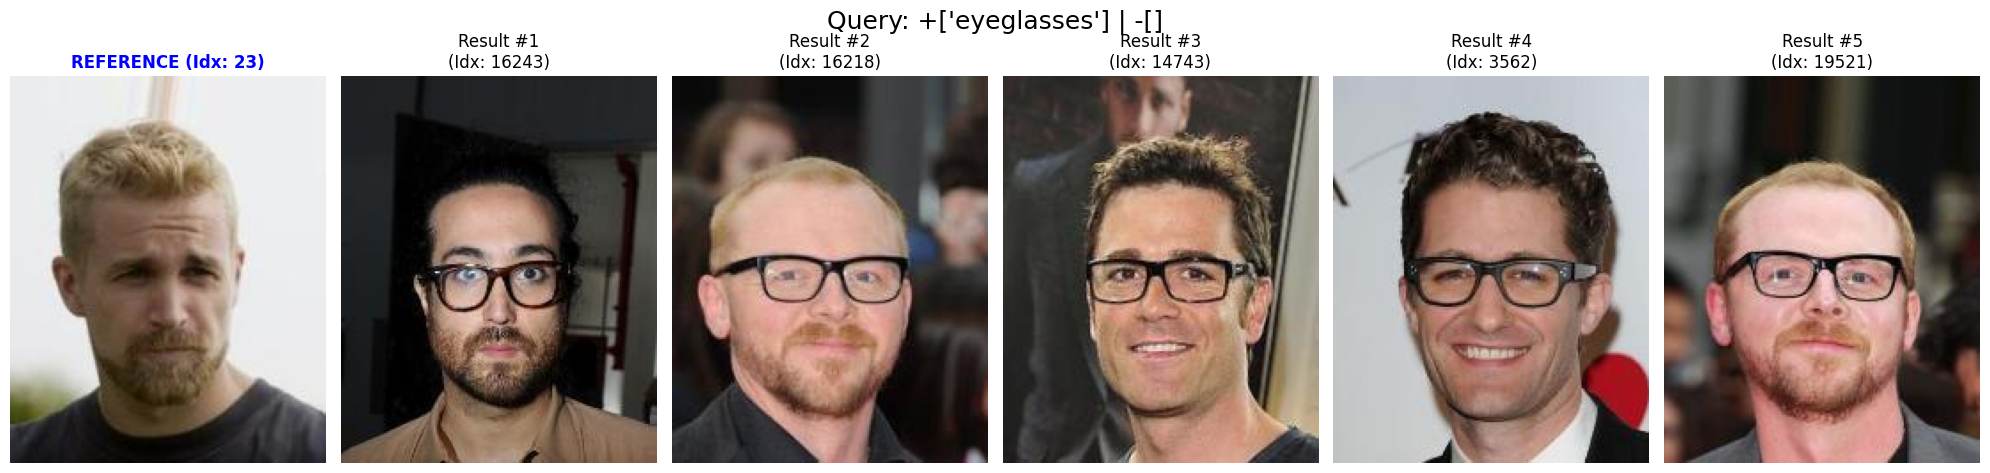

Query        : +Black_Hair, -Wavy_Hair
Pos attrs    : ['black hair']
Neg attrs    : ['wavy hair']
Reference idx: 71  (ref 11 of 2572 for this query)
GT count     : 5
MLP weights  : a=9.524  b=11.638  c=0.000
Hits in top-5: [] (0/5)


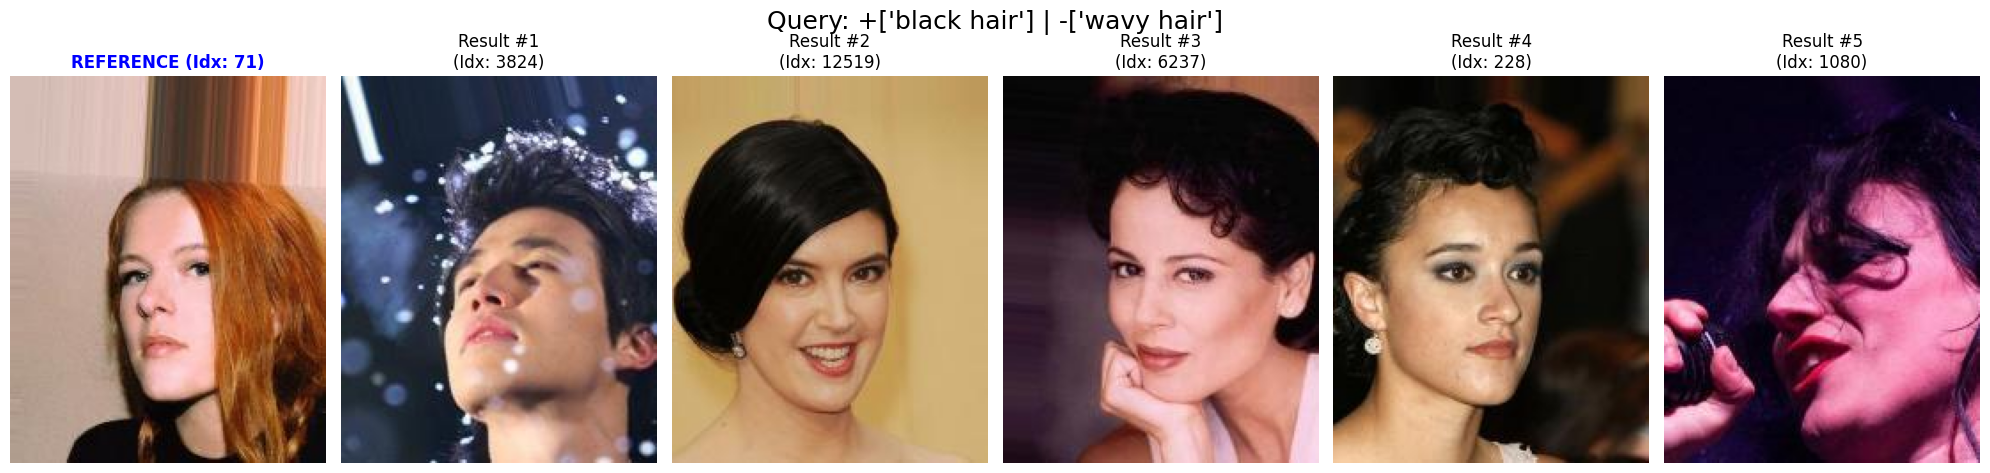

Query        : -Smiling, +Eyeglasses, +Wearing_Hat
Pos attrs    : ['eyeglasses', 'wearing hat']
Neg attrs    : ['smiling']
Reference idx: 662  (ref 4 of 79 for this query)
GT count     : 14
MLP weights  : a=58.110  b=47.369  c=0.000
Hits in top-5: [16325] (1/5)


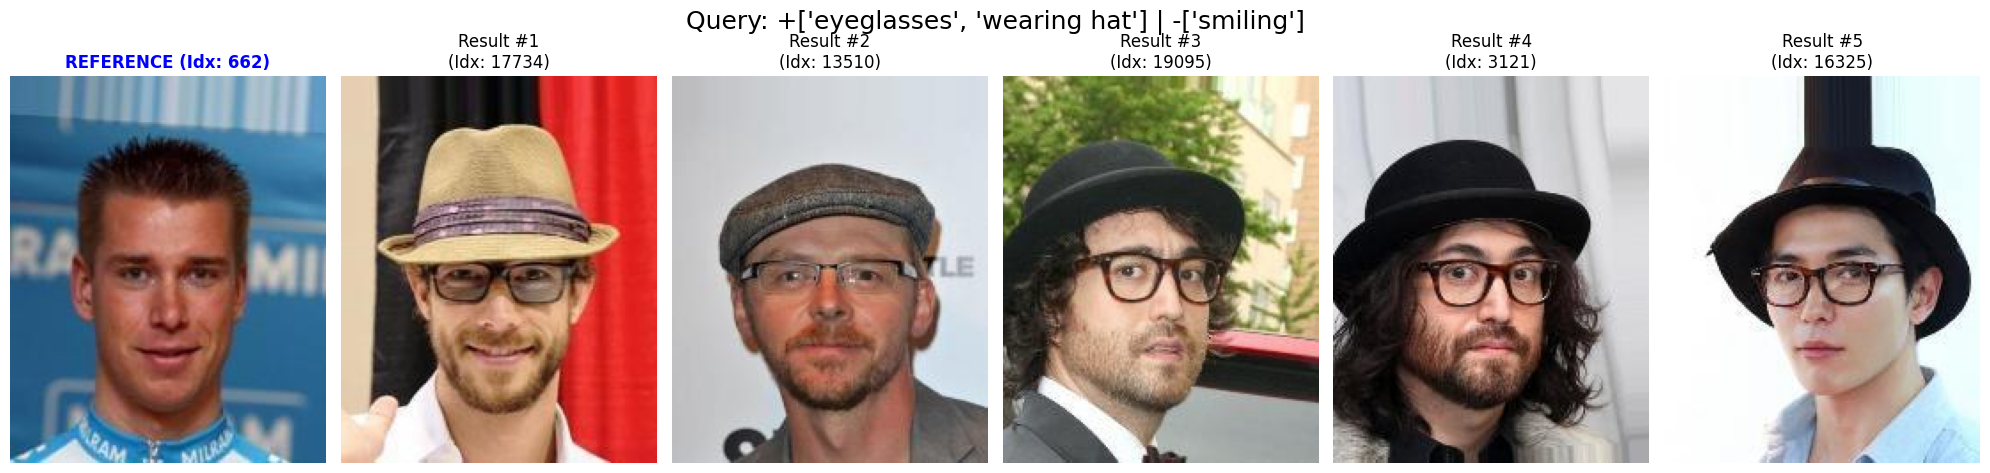

In [65]:
visualize_mlp_retrieval(
    mlp_model,
    annotations,
    projection_matrices,
    database_embeddings,
    celeba,
    query_idx = 1,    # 0–13, which query
    ref_pick  = 3,    # which reference image for that query
    top_k     = 5,
    device    = device,
)


visualize_mlp_retrieval(
    mlp_model,
    annotations,
    projection_matrices,
    database_embeddings,
    celeba,
    query_idx = 9,    # 0–13, which query
    ref_pick  = 10,    # which reference image for that query
    top_k     = 5,
    device    = device,
)

visualize_mlp_retrieval(
    mlp_model,
    annotations,
    projection_matrices,
    database_embeddings,
    celeba,
    query_idx = 12,    # 0–13, which query
    ref_pick  = 3,    # which reference image for that query
    top_k     = 5,
    device    = device,
)

Thanks for your attention!